<a href="https://colab.research.google.com/github/Digital-City-Lab-MUNI/Incremental-Learning-MycroftMinds/blob/main/notebooks/data_exploration.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Imports

In [73]:
# prompt: connect to drive

from google.colab import drive
drive.mount('/content/drive')


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

plt.rcParams['figure.figsize'] = (15,8)

# Load data

In [ ]:
# ============== Input your device id here =============#
DEVICE_ID = '2659da1f-9042-45c0-bf0a-625106aff7d1'      #
# ======================================================#

In [ ]:
import glob

#Colab version
#all_files = glob.glob('/content/drive/MyDrive/MyCroft Data/smart_meter_df_*.csv')

#Local version
all_files = glob.glob('../data/smart_meter_df_*.csv')


li = []

for filename in all_files:
    df = pd.read_csv(filename, index_col=None, header=0)
    li.append(df)

smart_meter_df = pd.concat(li, axis=0, ignore_index=True)
# Filter by device_id
meter_df = smart_meter_df[smart_meter_df.device_id == DEVICE_ID]
meter_df = meter_df.drop(columns=['device_id', 'serial_number'])
# get rid of timezone
meter_df['time'] = meter_df['time'].apply(lambda x: x[:-6])
# turn to datetime
meter_df['time'] = pd.to_datetime(meter_df['time'], infer_datetime_format =True)
# sort by 'time'
meter_df.sort_values(by=['time'], inplace=True)

print('\nShape:', meter_df.shape, '\n')
meter_df.head()


Shape: (4257624, 13) 



,time,device_id,serial_number,values_state,total_power_active,total_power_reactive,total_power_apparent,import_energy_active,export_energy_active,import_energy_reactive,export_energy_reactive,total_energy_active,total_energy_reactive
0,2024-01-01 00:00:01.818,e7803808-8743-4f1d-8c15-3d574a4bdf7c,73c48cf7-e53e-4548-802b-7971bf154f0c,NaN,101.053959,-635.689013,670.748839,912.812015,7788.926522,5179.064362,3565.426629,8656.644587,8767.779041
1,2024-01-01 00:00:03.671,a4b80cd7-5438-44cd-8257-c9ac81684822,d1e01b37-ad48-4df1-ad14-6e13d230b11a,NaN,580.350889,88.437225,590.806417,2087.377088,10.400000,582.029120,10.669146,2131.621335,589.340500
2,2024-01-01 00:00:05.524,2659da1f-9042-45c0-bf0a-625106aff7d1,9d57c045-ed26-4ee8-9039-302c16d8c478,NaN,88.760389,-1424.991659,1459.731053,8395.834012,5005.693161,5102.830154,7492.500722,13280.395948,12607.482568
3,2024-01-01 00:00:07.650,a806abdf-9261-4d98-abd4-a519248214f0,a39a6c1c-4992-4a91-be9b-ef9d4f411a51,NaN,10.472436,10.340116,10.496186,374.374368,10.400000,10.400000,246.197746,380.981669,10.400000
4,2024-01-01 00:00:08.667,fc529a25-d538-4c5b-b51e-2f27a3ce9f1a,0810a336-2fac-46e3-8029-57dda70375d7,NaN,10.593178,10.294157,10.629040,1111.791808,10.400000,10.400000,520.117300,1132.959947,10.400000


# EDA

In [ ]:
meter_df.describe()

,values_state,total_power_active,total_power_reactive,total_power_apparent,import_energy_active,export_energy_active,import_energy_reactive,export_energy_reactive,total_energy_active,total_energy_reactive
count,0.0,4.257622e+06,4.257622e+06,4.257622e+06,4.257622e+06,4.257622e+06,4.257622e+06,4.257622e+06,4.257624e+06,4.257624e+06
mean,NaN,7.039240e+01,-9.137543e+00,3.225422e+02,1.386879e+03,5.783489e+02,7.538119e+02,1.069650e+03,1.954853e+03,1.776910e+03
std,NaN,7.289893e+02,7.374262e+02,1.017329e+03,1.536003e+03,2.896844e+03,2.930607e+03,2.151089e+03,4.064968e+03,4.810699e+03
min,NaN,-2.301026e+04,-2.361441e+03,1.040000e+01,1.040000e+01,1.040000e+01,1.040000e+01,1.040000e+01,1.040000e+01,1.040000e+01
25%,NaN,1.045980e+01,-1.047457e+02,2.254765e+01,5.907761e+02,1.040000e+01,1.352155e+01,1.102317e+02,5.907848e+02,1.992162e+02
50%,NaN,5.759210e+01,-2.834568e+00,1.376931e+02,1.052124e+03,1.040000e+01,6.605899e+01,3.185162e+02,1.056701e+03,6.116024e+02
75%,NaN,1.162034e+02,1.040000e+01,2.799125e+02,1.672109e+03,1.040000e+01,3.681168e+02,9.121748e+02,1.756802e+03,1.161788e+03
max,NaN,1.127072e+04,1.420497e+04,2.601259e+04,9.919320e+03,2.737583e+04,2.975262e+04,1.573584e+04,3.702078e+04,4.540840e+04


## Missing data

In [ ]:
pd.concat(
    [meter_df.count(), meter_df.isna().sum(), (meter_df.isna().sum()/meter_df.shape[0])*100],
    axis=1).rename(columns={0:'total', 1:'missing', 2:'missing_perc'})

,total,missing,missing_perc
time,4257624,0,0.000000
device_id,4257624,0,0.000000
serial_number,4257624,0,0.000000
values_state,0,4257624,100.000000
total_power_active,4257622,2,0.000047
total_power_reactive,4257622,2,0.000047
total_power_apparent,4257622,2,0.000047
import_energy_active,4257622,2,0.000047
export_energy_active,4257622,2,0.000047
import_energy_reactive,4257622,2,0.000047


,index,time,total_power_active,total_power_reactive,total_power_apparent,import_energy_active,export_energy_active,import_energy_reactive,export_energy_reactive,total_energy_active,total_energy_reactive
0,2,2024-01-01 00:00:05.524,88.760389,-1424.991659,1459.731053,8395.834012,5005.693161,5102.830154,7492.500722,13280.395948,12607.482568
1,43,2024-01-01 00:05:05.632,93.827445,-1328.882251,1612.680556,8510.173038,5040.204711,4998.361291,7591.277909,13115.467897,13054.991009
2,84,2024-01-01 00:10:05.715,96.882494,-1181.411784,1271.391968,8889.228446,4984.443049,5031.016364,7777.695840,13097.270411,12691.143246
3,125,2024-01-01 00:15:05.945,92.438946,-1178.174567,1276.552006,8546.699029,5081.838768,5069.019403,7548.126917,13794.098831,12952.747359
4,166,2024-01-01 00:20:05.104,107.808087,-1223.795237,1297.693855,8613.908909,4960.374671,5310.570328,7643.704649,13172.015915,12601.853955


In [ ]:
meter_df.describe()

,index,time,total_power_active,total_power_reactive,total_power_apparent,import_energy_active,export_energy_active,import_energy_reactive,export_energy_reactive,total_energy_active,total_energy_reactive
count,1.038620e+05,103862,103862.000000,103862.000000,103862.000000,103862.000000,103862.000000,103862.000000,103862.000000,103862.000000,103862.000000
mean,2.128868e+06,2024-06-30 20:50:59.681171712,-2219.577551,1801.154085,4604.276282,8822.856850,15610.701470,16876.682789,11072.453367,24424.482665,27934.989639
min,2.000000e+00,2024-01-01 00:00:05.524000,-23010.263048,-2361.440717,624.733859,7838.201765,4709.768270,4884.839227,7193.379711,12643.062211,12155.892482
25%,1.064535e+06,2024-03-31 05:11:20.100999936,-4097.246077,-1422.197260,1498.243443,8617.838892,7956.991507,9682.264997,9704.044762,16583.926221,19389.355665
50%,2.128840e+06,2024-06-29 13:42:35.677499904,45.622311,-1132.336764,1815.012137,8813.392910,15971.914785,17068.944873,10967.235904,24774.020957,28007.748038
75%,3.193264e+06,2024-10-02 07:04:36.488999936,102.701109,4990.824133,7546.680505,9020.333490,23262.124549,24140.487346,12436.100536,32209.325779,36551.184430
max,4.257613e+06,2024-12-31 23:55:51.017000,6121.439983,14204.972043,26012.589650,9919.320388,27375.830136,29752.620497,15735.842954,37020.780839,45408.404811
std,1.229035e+06,NaN,3512.299607,4212.775634,4296.500369,288.874510,7404.336450,7466.519670,1832.616248,7632.472290,9260.561275


`export_energy_active` mostly has 0 std, but not for device *2659da1f-9042-45c0-bf0a-625106aff7d1*

## Range of an individual meter

In [ ]:
print('Min:', meter_df['time'].min(),'\nMax:', meter_df['time'].max())

Min: 2024-01-01 00:00:05.524000 
Max: 2024-12-31 23:55:51.017000


## Time frequency of data

In [ ]:
print("Describe:")
display(meter_df.set_index('time').resample('h').size().describe())

print('\nHead:')
display(meter_df.set_index('time').resample('h').size().sort_values().head(45))

print('\nTail:')
meter_df.set_index('time').resample('h').size().sort_values().tail(5)

Describe:


,0
count,8784.000000
mean,11.823998
std,1.424877
min,0.000000
25%,12.000000
50%,12.000000
75%,12.000000
max,24.000000



Head:


,0
time,
2024-12-06 00:00:00,0
2024-11-20 00:00:00,0
2024-11-20 01:00:00,0
2024-11-20 02:00:00,0
2024-11-20 04:00:00,0
2024-11-20 03:00:00,0
2024-11-20 05:00:00,0
2024-11-20 06:00:00,0
2024-11-19 23:00:00,0



Tail:


,0
time,
2024-05-05 15:00:00,12
2024-05-05 16:00:00,12
2024-05-07 01:00:00,12
2024-05-07 03:00:00,12
2024-10-27 02:00:00,24


## Time differences for the meter

In [ ]:
meter_time_diff = meter_df['time'].diff().dropna().sort_values()  # drop NAT for the 1st value

print("Describe:")
display(meter_time_diff.describe())

print('\nHead:')
display(meter_time_diff.head(15))

print('\nTail:')
meter_time_diff.tail(42)

Describe:


,time
count,103861
mean,0 days 00:05:04.466021827
std,0 days 00:17:51.682194540
min,0 days 00:00:00.015000
25%,0 days 00:04:59.966000
50%,0 days 00:05:00.075000
75%,0 days 00:05:00.194000
max,3 days 22:58:09.799000



Head:


,time
85031,0 days 00:00:00.015000
85029,0 days 00:00:00.029000
85033,0 days 00:00:00.071000
85043,0 days 00:00:00.241000
85041,0 days 00:00:00.287000
85037,0 days 00:00:00.377000
85047,0 days 00:00:00.452000
85049,0 days 00:00:00.774000
85045,0 days 00:00:08.589000
85035,0 days 00:00:08.636000



Tail:


,time
81705,0 days 00:05:13.942000
80684,0 days 00:05:22.469000
76838,0 days 00:05:22.531000
74022,0 days 00:06:51.506000
74024,0 days 00:09:05.054000
37787,0 days 00:09:59.120000
12458,0 days 00:09:59.396000
71131,0 days 00:09:59.572000
63769,0 days 00:09:59.598000
24663,0 days 00:09:59.835000


#### Look at periods where the differences are less than 5 minutes (includes two entries to see the difference in data)
Read the table from the beginning and consider entries in pairs:
- 76838 - 78839 (first pair)
- 78508 - 78509 (second pair)
- ...
- 85048 - 85049 (last pair)


In [ ]:
less_5_min_plus_next = meter_time_diff.head(15).index.append(
    meter_time_diff.head(15).index-1
    )

meter_df.loc[less_5_min_plus_next][['time','total_power_active']].sort_values('time').join(
    meter_time_diff.head(15), rsuffix='_difference')

,time,total_power_active,time_difference
76838,2024-09-28 14:56:14.136,-1384.655917,NaT
76839,2024-09-28 15:00:51.128,-1581.130037,0 days 00:04:36.992000
78508,2024-10-04 10:06:04.930,-3888.518660,NaT
78509,2024-10-04 10:10:50.941,-3178.431655,0 days 00:04:46.011000
82028,2024-10-16 16:11:05.021,-3083.969929,NaT
82029,2024-10-16 16:15:51.092,-2972.740049,0 days 00:04:46.071000
85026,2024-10-27 02:00:51.364,98.422291,NaT
85027,2024-10-27 02:01:00.267,97.428032,0 days 00:00:08.903000
85028,2024-10-27 02:05:51.368,105.977909,NaT
85029,2024-10-27 02:05:51.397,108.601926,0 days 00:00:00.029000


Here we can see that the `2024-10-27 02:00:00` hours is doubled for some reason, but some inconsistencies also happen in other time periods

#### Look at periods where the differences are bigger than 5 minutes (includes two entries to see the difference in data)
Read the table from the beginning and consider entries in pairs:

In [ ]:
more_5_min_plus_next = meter_time_diff.tail(25).index.append(
    meter_time_diff.tail(25).index-1
    )

meter_df.loc[more_5_min_plus_next][['time','total_power_active']].sort_values('time').join(
    meter_time_diff.tail(25), rsuffix='_difference')

,time,total_power_active,time_difference
25938,2024-03-31 01:55:05.908,100.655070,NaT
25939,2024-03-31 03:00:05.313,95.651194,0 days 01:04:59.405000
40100,2024-05-19 07:15:05.951,-2304.442240,NaT
40101,2024-05-19 08:20:05.818,-6478.552994,0 days 01:04:59.867000
40131,2024-05-19 10:50:05.270,-3347.510255,NaT
40132,2024-05-19 11:45:05.473,-2996.954267,0 days 00:55:00.203000
43446,2024-05-30 23:55:05.958,100.556435,NaT
43447,2024-05-31 02:45:06.074,101.105650,0 days 02:50:00.116000
61953,2024-08-03 08:55:05.229,-2103.199487,NaT
61954,2024-08-03 09:25:05.815,-2191.327646,0 days 00:30:00.586000


Most of the inconsistencies are happening in September, but the others are randomly spread throughout the time

## Correlation analysis

<Axes: >

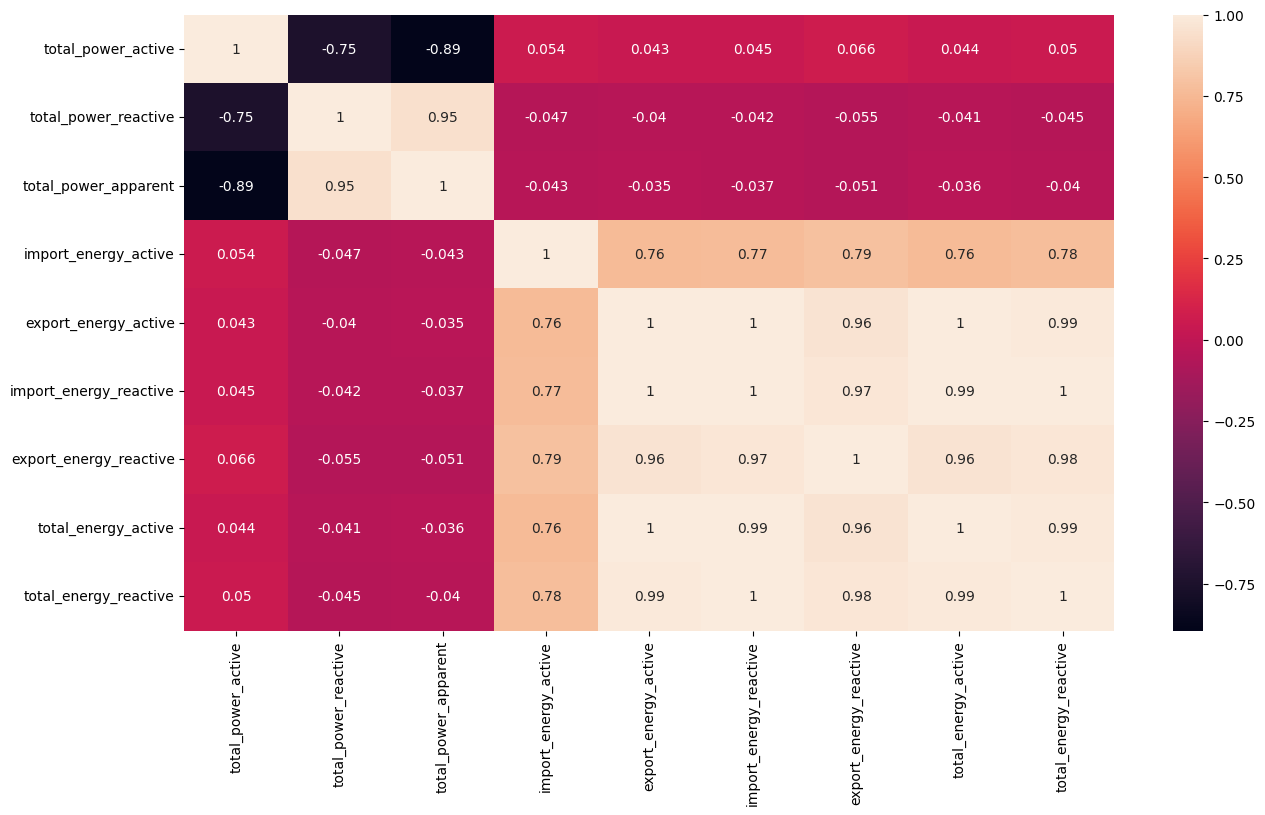

In [ ]:
sns.heatmap(meter_df.drop(columns=['index', 'time']).fillna('median').corr(), annot=True)

<Axes: >

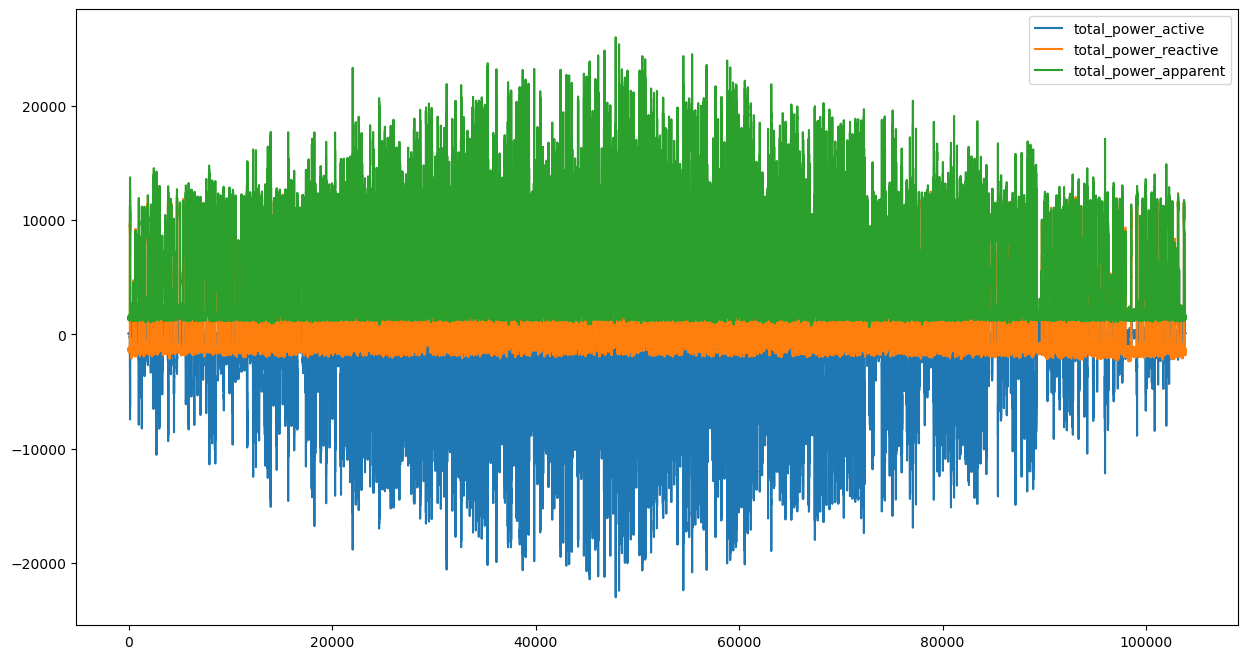

In [ ]:
power_cols = meter_df.columns[meter_df.columns.str.contains('power')]
meter_df[power_cols].plot()

<Axes: >

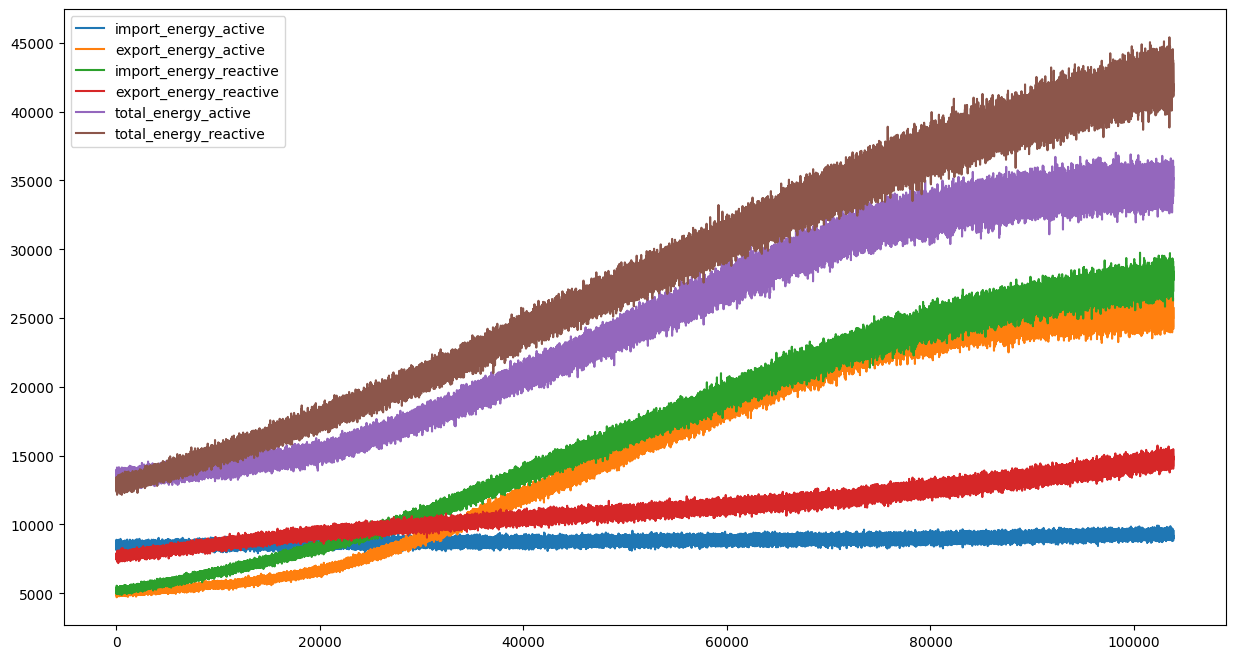

In [ ]:
energy_cols = meter_df.columns[meter_df.columns.str.contains('energy')]
meter_df[energy_cols].plot()

## Plotting the data

### Original (5 min)

#### `total_energy_active`

<Axes: xlabel='time', ylabel='total_energy_active'>

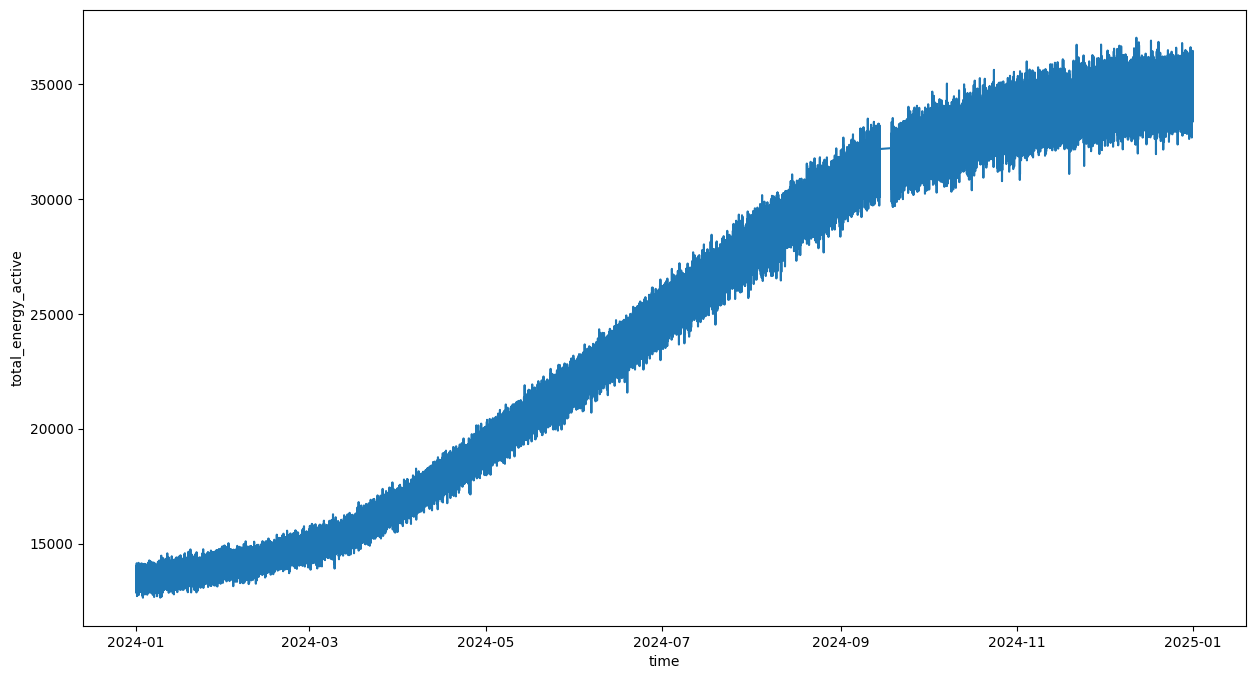

In [ ]:
plt.figure(figsize=(15,8))
sns.lineplot(x=meter_df['time'], y=meter_df['total_energy_active'])

#### `total_energy_active.diff(1)`

<Axes: xlabel='time', ylabel='total_energy_active'>

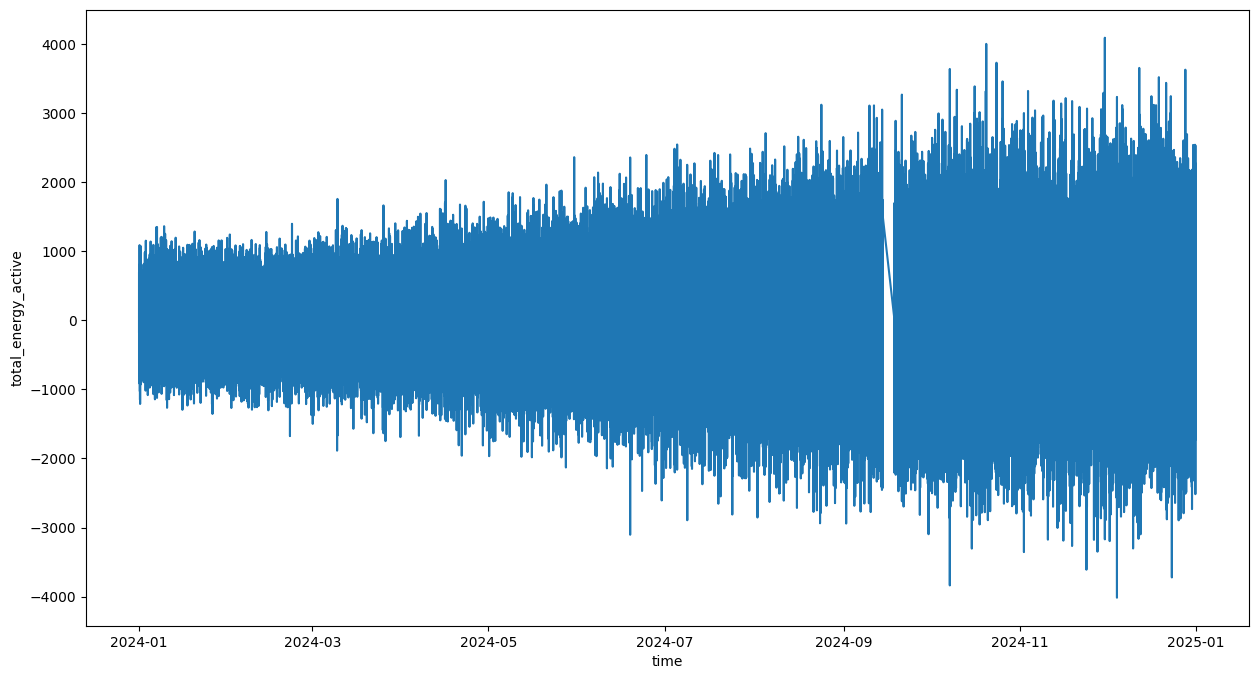

In [ ]:
sns.lineplot(x=meter_df['time'], y=meter_df['total_energy_active'].diff(1))

#### `total_power_active`


<Axes: xlabel='time', ylabel='total_power_active'>

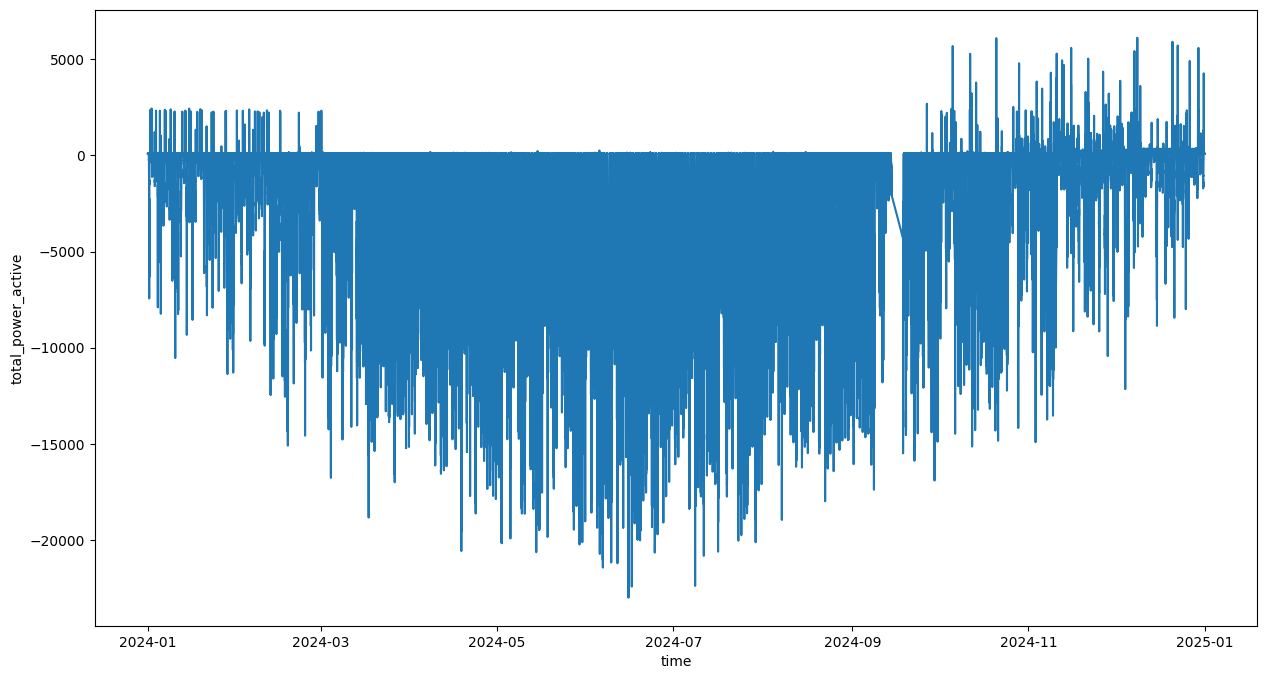

In [ ]:
sns.lineplot(x=meter_df['time'], y=meter_df['total_power_active'])

In [ ]:
meter_df['total_power_active'].describe()

,total_power_active
count,103862.000000
mean,-2219.577551
std,3512.299607
min,-23010.263048
25%,-4097.246077
50%,45.622311
75%,102.701109
max,6121.439983


<Axes: xlabel='time', ylabel='total_power_active'>

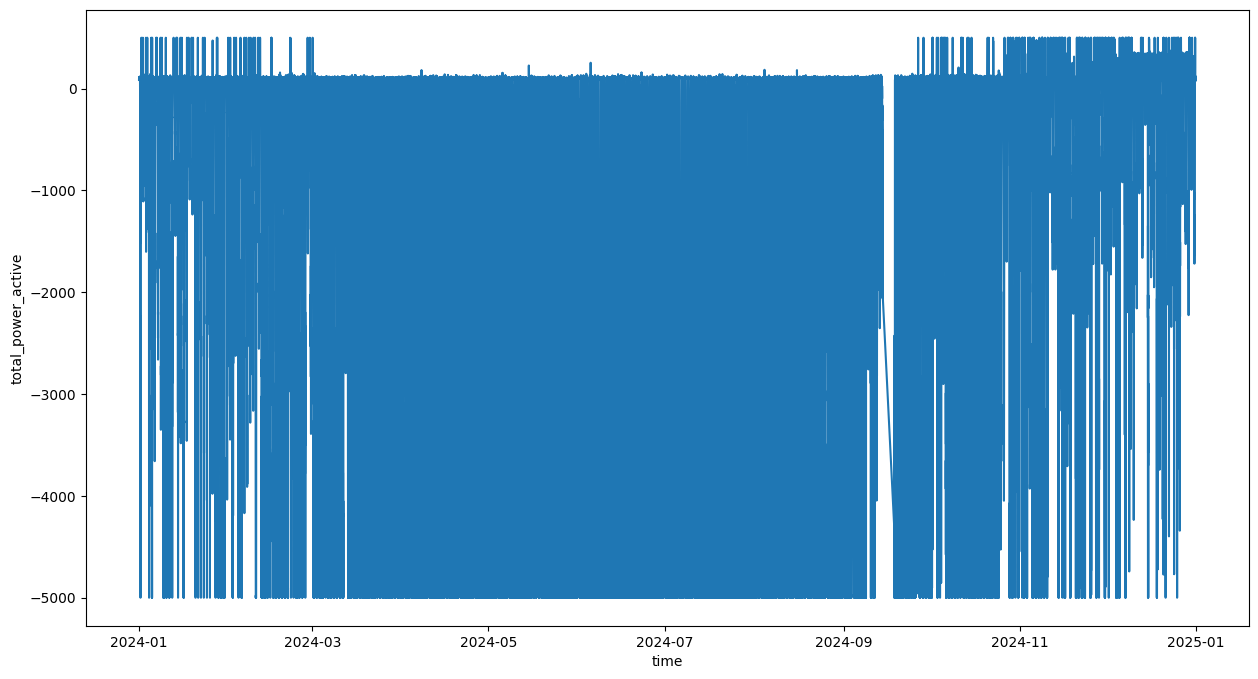

In [ ]:
sns.lineplot(x=meter_df['time'], y=meter_df['total_power_active'].clip(-5000, 500))

#### Missing data in September

<Axes: xlabel='time', ylabel='total_energy_active'>

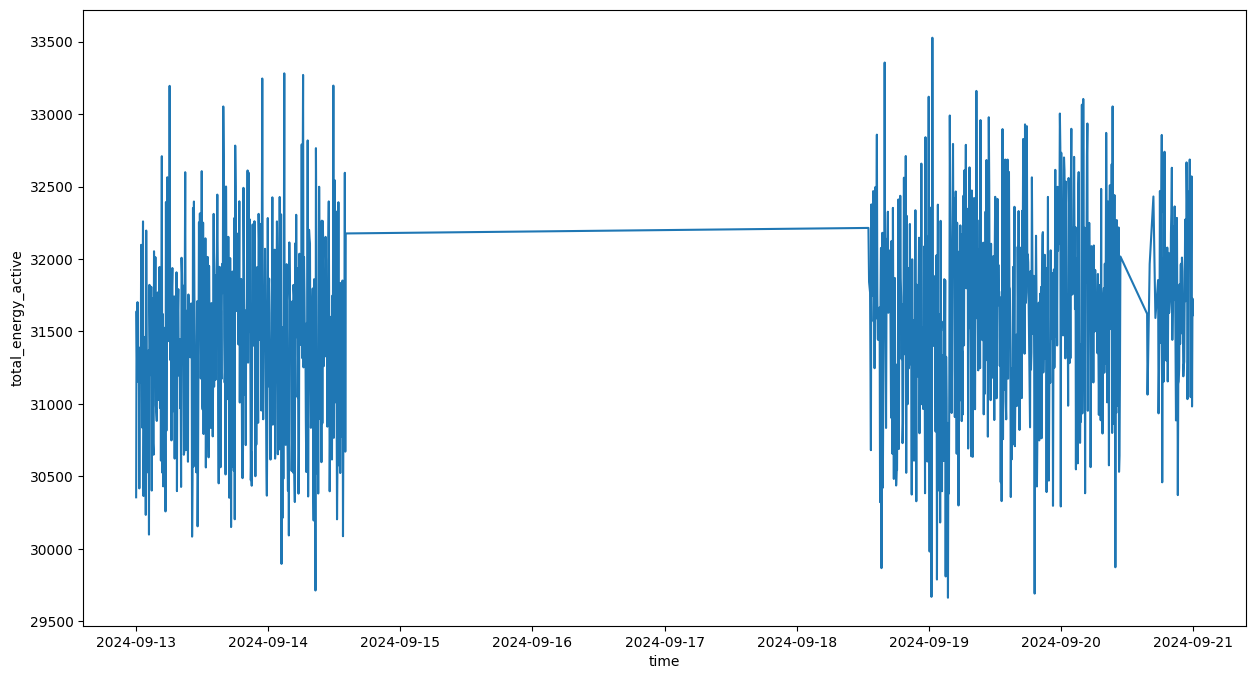

In [ ]:
date_range = pd.date_range('2024-09-13', '2024-09-21', freq='min')
sns.lineplot(
    x=meter_df['time'][meter_df['time'].dt.floor('min').isin(date_range)],
    y=meter_df[meter_df['time'].dt.floor('min').isin(date_range)]['total_energy_active']
    )

<Axes: xlabel='time', ylabel='total_power_active'>

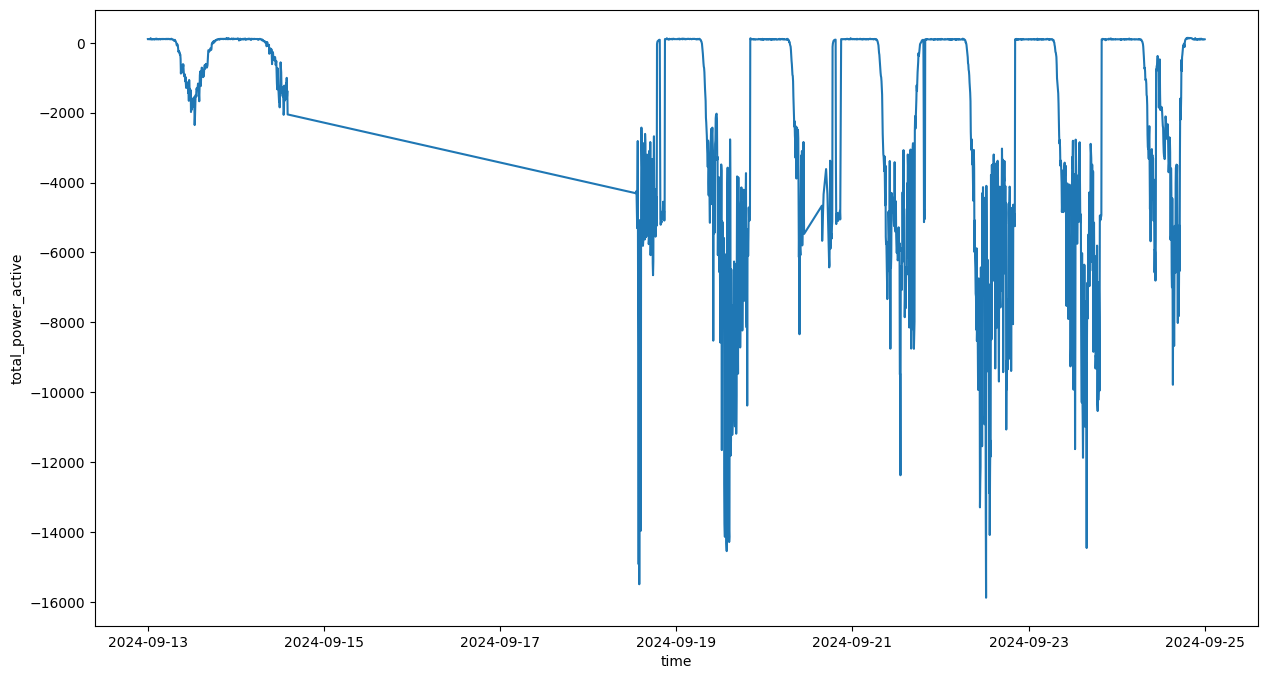

In [ ]:
date_range = pd.date_range('2024-09-13', '2024-09-25', freq='min')
sns.lineplot(
    x=meter_df['time'][meter_df['time'].dt.floor('min').isin(date_range)],
    y=meter_df[meter_df['time'].dt.floor('min').isin(date_range)]['total_power_active']
    )

### Hourly

##### `total_energy_active`

DatetimeIndex(['2024-01-01 00:00:00', '2024-01-01 01:00:00',
               '2024-01-01 02:00:00', '2024-01-01 03:00:00',
               '2024-01-01 04:00:00', '2024-01-01 05:00:00',
               '2024-01-01 06:00:00', '2024-01-01 07:00:00',
               '2024-01-01 08:00:00', '2024-01-01 09:00:00',
               ...
               '2024-12-31 14:00:00', '2024-12-31 15:00:00',
               '2024-12-31 16:00:00', '2024-12-31 17:00:00',
               '2024-12-31 18:00:00', '2024-12-31 19:00:00',
               '2024-12-31 20:00:00', '2024-12-31 21:00:00',
               '2024-12-31 22:00:00', '2024-12-31 23:00:00'],
              dtype='datetime64[ns]', length=8784, freq='h')


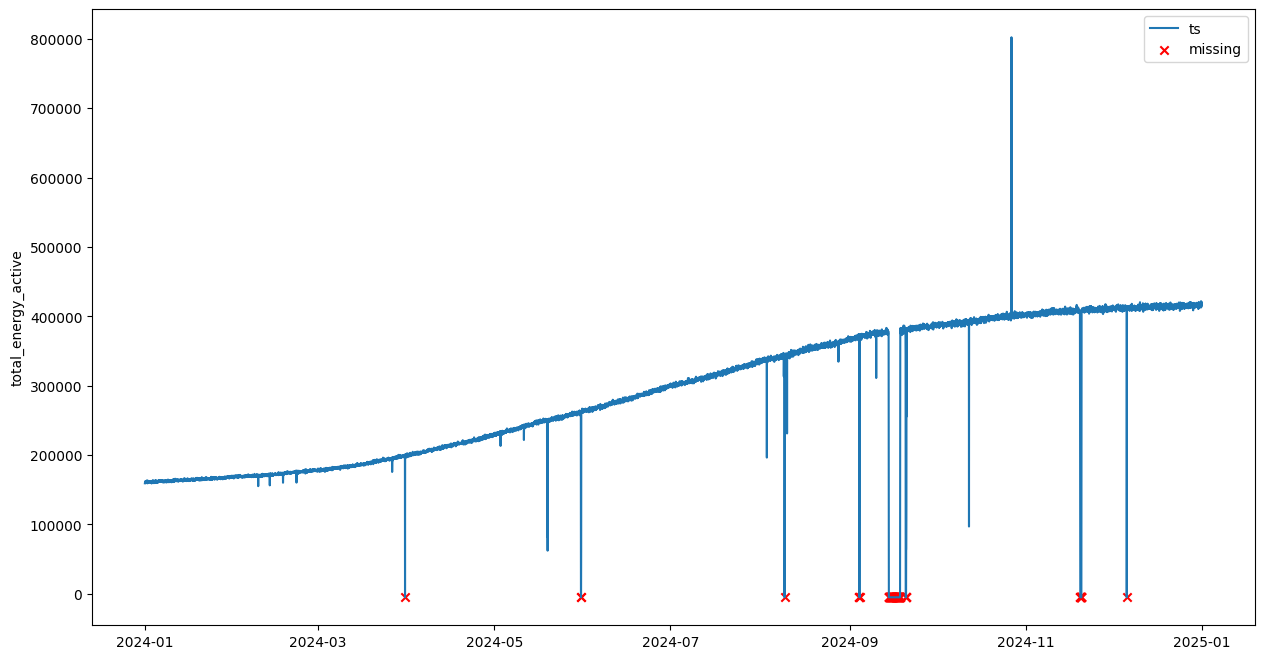

In [ ]:
plt.figure(figsize=(15,8))
hourly_meter_df = meter_df.groupby(meter_df['time'].dt.floor('h'))
full_range = pd.DataFrame(
    index=pd.date_range(pd.DatetimeIndex(hourly_meter_df.indices.keys()).min(),\
                        pd.DatetimeIndex(hourly_meter_df.indices.keys()).max(), freq='h')
    )
print(full_range.index)
tot_eng_hour_endog = full_range.join(hourly_meter_df['total_energy_active'].sum(), how='left').squeeze()

sns.lineplot(tot_eng_hour_endog.fillna(-5000), label='ts')
plt.scatter(
    x=tot_eng_hour_endog[tot_eng_hour_endog.isna()].index,
    y=[-5000]*tot_eng_hour_endog[tot_eng_hour_endog.isna()].shape[0],
    color='red',
    marker='x',
    label='missing'
    )

plt.legend()

##### `total_energy_active.diff(1)`

DatetimeIndex(['2024-01-01 00:00:00', '2024-01-01 01:00:00',
               '2024-01-01 02:00:00', '2024-01-01 03:00:00',
               '2024-01-01 04:00:00', '2024-01-01 05:00:00',
               '2024-01-01 06:00:00', '2024-01-01 07:00:00',
               '2024-01-01 08:00:00', '2024-01-01 09:00:00',
               ...
               '2024-12-31 14:00:00', '2024-12-31 15:00:00',
               '2024-12-31 16:00:00', '2024-12-31 17:00:00',
               '2024-12-31 18:00:00', '2024-12-31 19:00:00',
               '2024-12-31 20:00:00', '2024-12-31 21:00:00',
               '2024-12-31 22:00:00', '2024-12-31 23:00:00'],
              dtype='datetime64[ns]', length=8784, freq='h')


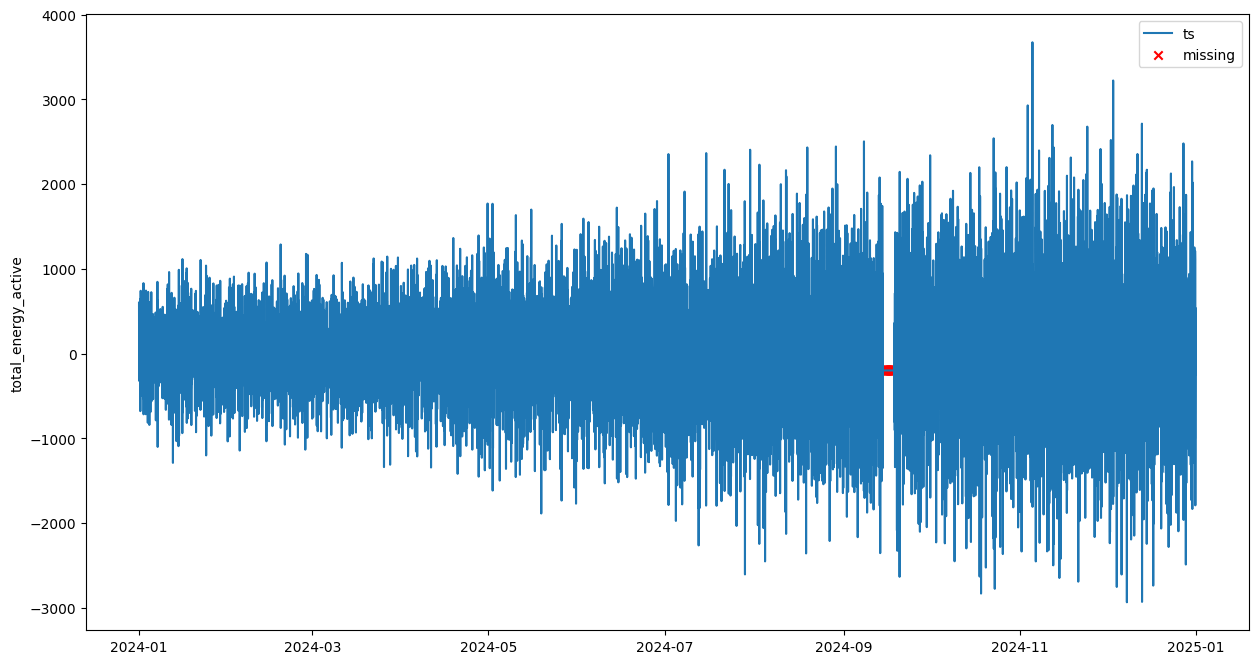

In [ ]:
plt.figure(figsize=(15,8))
hourly_meter_df = meter_df.diff(1).groupby(meter_df['time'].dt.floor('h'))
full_range = pd.DataFrame(
    index=pd.date_range(pd.DatetimeIndex(hourly_meter_df.indices.keys()).min(),\
                        pd.DatetimeIndex(hourly_meter_df.indices.keys()).max(), freq='h')
    )
print(full_range.index)
tot_eng_diff_hour_endog = full_range.join(hourly_meter_df['total_energy_active'].sum(), how='left').squeeze()

sns.lineplot(tot_eng_diff_hour_endog.fillna(-200), label='ts')
plt.scatter(
    x=tot_eng_diff_hour_endog[tot_eng_diff_hour_endog.isna()].index,
    y=[-200]*tot_eng_diff_hour_endog[tot_eng_diff_hour_endog.isna()].shape[0],
    color='red',
    marker='x',
    label='missing'
    )

plt.legend()

##### `total_power_active`


DatetimeIndex(['2024-01-01 00:00:00', '2024-01-01 01:00:00',
               '2024-01-01 02:00:00', '2024-01-01 03:00:00',
               '2024-01-01 04:00:00', '2024-01-01 05:00:00',
               '2024-01-01 06:00:00', '2024-01-01 07:00:00',
               '2024-01-01 08:00:00', '2024-01-01 09:00:00',
               ...
               '2024-12-31 14:00:00', '2024-12-31 15:00:00',
               '2024-12-31 16:00:00', '2024-12-31 17:00:00',
               '2024-12-31 18:00:00', '2024-12-31 19:00:00',
               '2024-12-31 20:00:00', '2024-12-31 21:00:00',
               '2024-12-31 22:00:00', '2024-12-31 23:00:00'],
              dtype='datetime64[ns]', length=8784, freq='h')


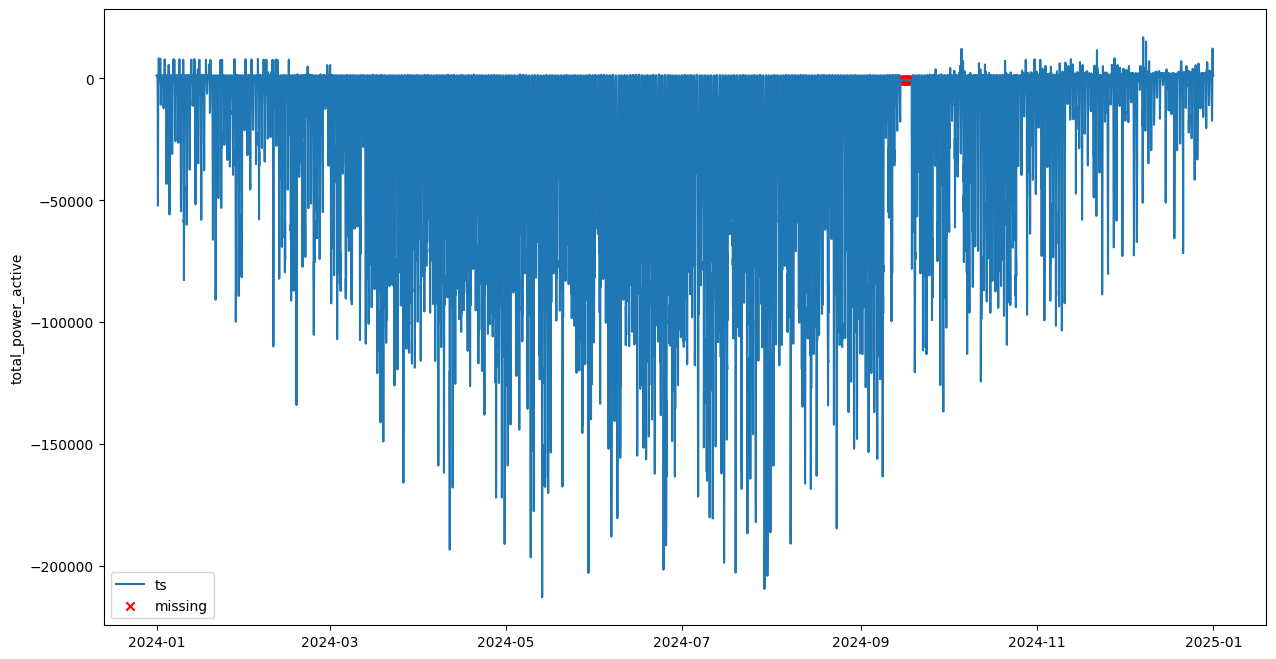

In [ ]:
plt.figure(figsize=(15,8))
hourly_meter_df = meter_df.groupby(meter_df['time'].dt.floor('h'))
full_range = pd.DataFrame(
    index=pd.date_range(pd.DatetimeIndex(hourly_meter_df.indices.keys()).min(),\
                        pd.DatetimeIndex(hourly_meter_df.indices.keys()).max(), freq='h')
    )
print(full_range.index)
tot_pow_hour_endog = full_range.join(hourly_meter_df['total_power_active'].sum(), how='left').squeeze()

sns.lineplot(tot_pow_hour_endog.fillna(-700), label='ts')
plt.scatter(
    x=tot_pow_hour_endog[tot_pow_hour_endog.isna()].index,
    y=[-700]*tot_pow_hour_endog[tot_pow_hour_endog.isna()].shape[0],
    color='red',
    marker='x',
    label='missing'
    )

plt.legend()

#### Daily

##### `total_energy_active`

DatetimeIndex(['2024-01-01', '2024-01-02', '2024-01-03', '2024-01-04',
               '2024-01-05', '2024-01-06', '2024-01-07', '2024-01-08',
               '2024-01-09', '2024-01-10',
               ...
               '2024-12-22', '2024-12-23', '2024-12-24', '2024-12-25',
               '2024-12-26', '2024-12-27', '2024-12-28', '2024-12-29',
               '2024-12-30', '2024-12-31'],
              dtype='datetime64[ns]', length=366, freq='D')


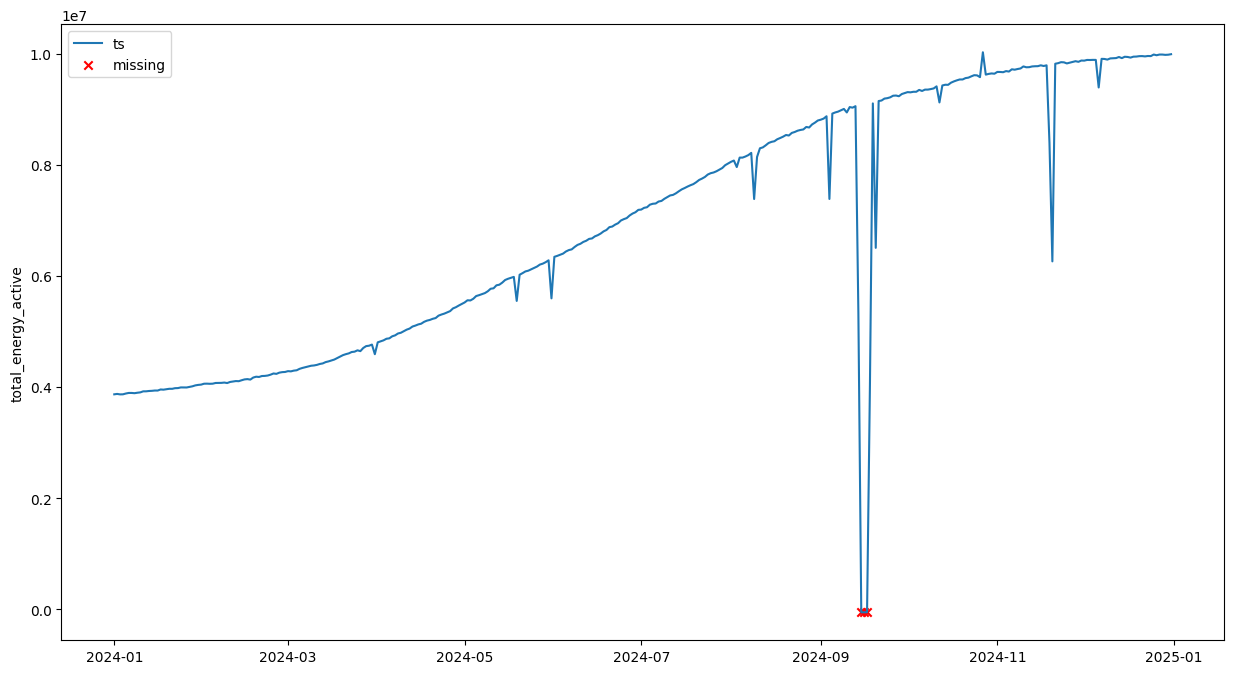

In [ ]:
plt.figure(figsize=(15,8))
daily_meter_df = meter_df.groupby(meter_df['time'].dt.floor('d'))

full_range = pd.DataFrame(
    index=pd.date_range(pd.DatetimeIndex(hourly_meter_df.indices.keys()).min(),\
                        pd.DatetimeIndex(hourly_meter_df.indices.keys()).max(), freq='d')
    )
print(full_range.index)

tot_eng_day_endog = full_range.join(daily_meter_df['total_energy_active'].sum(), how='left').squeeze()

sns.lineplot(tot_eng_day_endog.fillna(-50000), label='ts')
plt.scatter(
    x=tot_eng_day_endog[tot_eng_day_endog.isna()].index,
    y=[-50000]*tot_eng_day_endog[tot_eng_day_endog.isna()].shape[0],
    color='red',
    marker='x',
    label='missing'
    )

plt.legend()

##### `total_energy_active.diff(1)`

DatetimeIndex(['2024-01-01', '2024-01-02', '2024-01-03', '2024-01-04',
               '2024-01-05', '2024-01-06', '2024-01-07', '2024-01-08',
               '2024-01-09', '2024-01-10',
               ...
               '2024-12-22', '2024-12-23', '2024-12-24', '2024-12-25',
               '2024-12-26', '2024-12-27', '2024-12-28', '2024-12-29',
               '2024-12-30', '2024-12-31'],
              dtype='datetime64[ns]', length=366, freq='D')


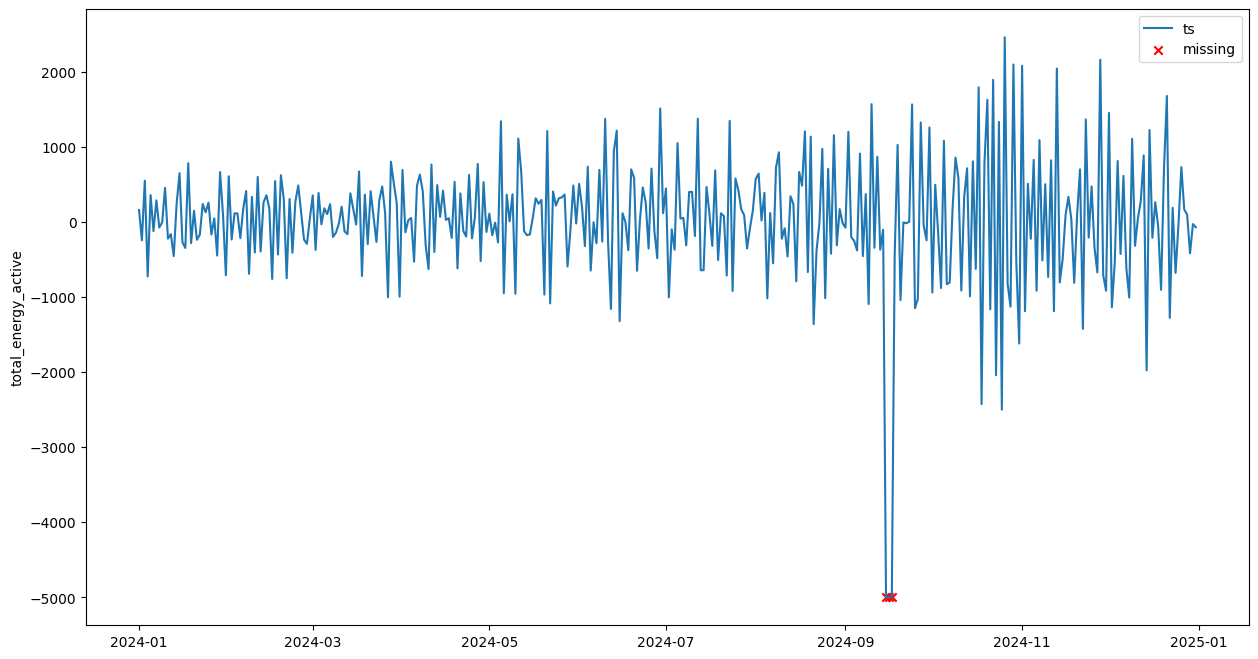

In [ ]:
plt.figure(figsize=(15,8))
daily_meter_df = meter_df.diff(1).groupby(meter_df['time'].dt.floor('d'))

full_range = pd.DataFrame(
    index=pd.date_range(pd.DatetimeIndex(hourly_meter_df.indices.keys()).min(),\
                        pd.DatetimeIndex(hourly_meter_df.indices.keys()).max(), freq='d')
    )
print(full_range.index)

tot_eng_day_endog = full_range.join(daily_meter_df['total_energy_active'].sum(), how='left').squeeze()

sns.lineplot(tot_eng_day_endog.fillna(-5000), label='ts')
plt.scatter(
    x=tot_eng_day_endog[tot_eng_day_endog.isna()].index,
    y=[-5000]*tot_eng_day_endog[tot_eng_day_endog.isna()].shape[0],
    color='red',
    marker='x',
    label='missing'
    )

plt.legend()

##### `total_power_active`


DatetimeIndex(['2024-01-01', '2024-01-02', '2024-01-03', '2024-01-04',
               '2024-01-05', '2024-01-06', '2024-01-07', '2024-01-08',
               '2024-01-09', '2024-01-10',
               ...
               '2024-12-22', '2024-12-23', '2024-12-24', '2024-12-25',
               '2024-12-26', '2024-12-27', '2024-12-28', '2024-12-29',
               '2024-12-30', '2024-12-31'],
              dtype='datetime64[ns]', length=366, freq='D')


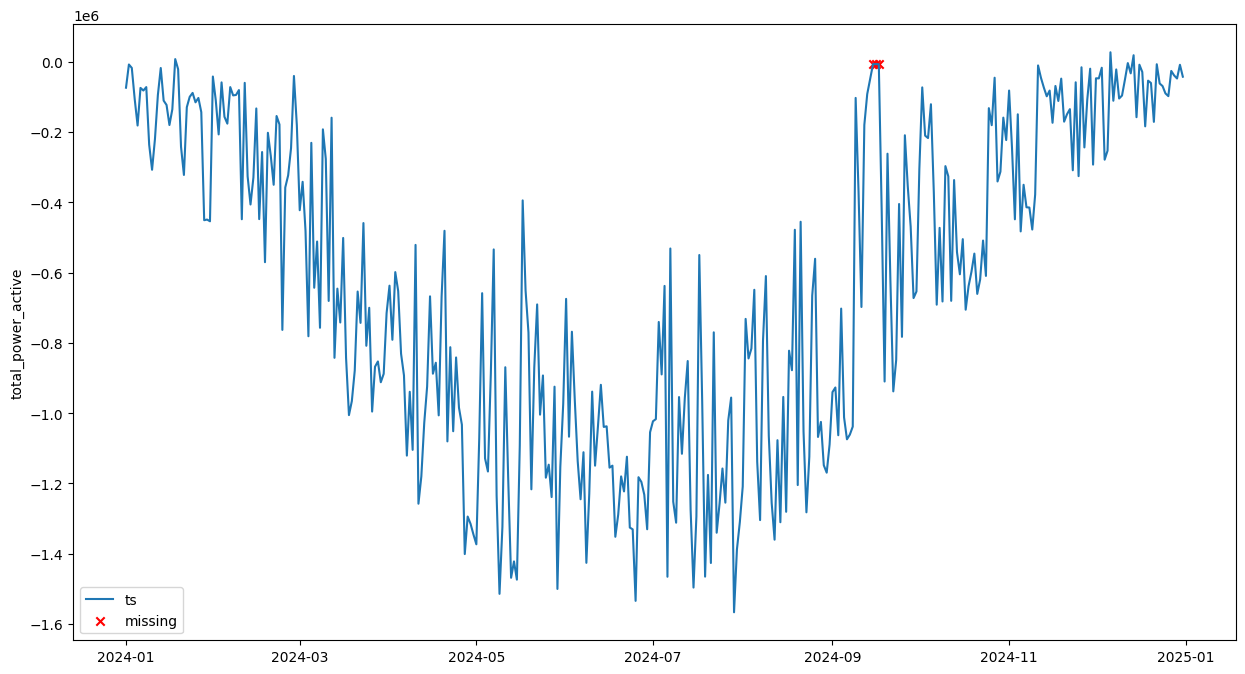

In [ ]:
plt.figure(figsize=(15,8))
daily_meter_df = meter_df.groupby(meter_df['time'].dt.floor('d'))

full_range = pd.DataFrame(
    index=pd.date_range(pd.DatetimeIndex(hourly_meter_df.indices.keys()).min(),\
                        pd.DatetimeIndex(hourly_meter_df.indices.keys()).max(), freq='d')
    )
print(full_range.index)

tot_pow_day_endog = full_range.join(daily_meter_df['total_power_active'].sum(), how='left').squeeze()

sns.lineplot(tot_pow_day_endog.fillna(-7000), label='ts')
plt.scatter(
    x=tot_pow_day_endog[tot_pow_day_endog.isna()].index,
    y=[-7000]*tot_pow_day_endog[tot_pow_day_endog.isna()].shape[0],
    color='red',
    marker='x',
    label='missing'
    )

plt.legend()

## Frequency analysis

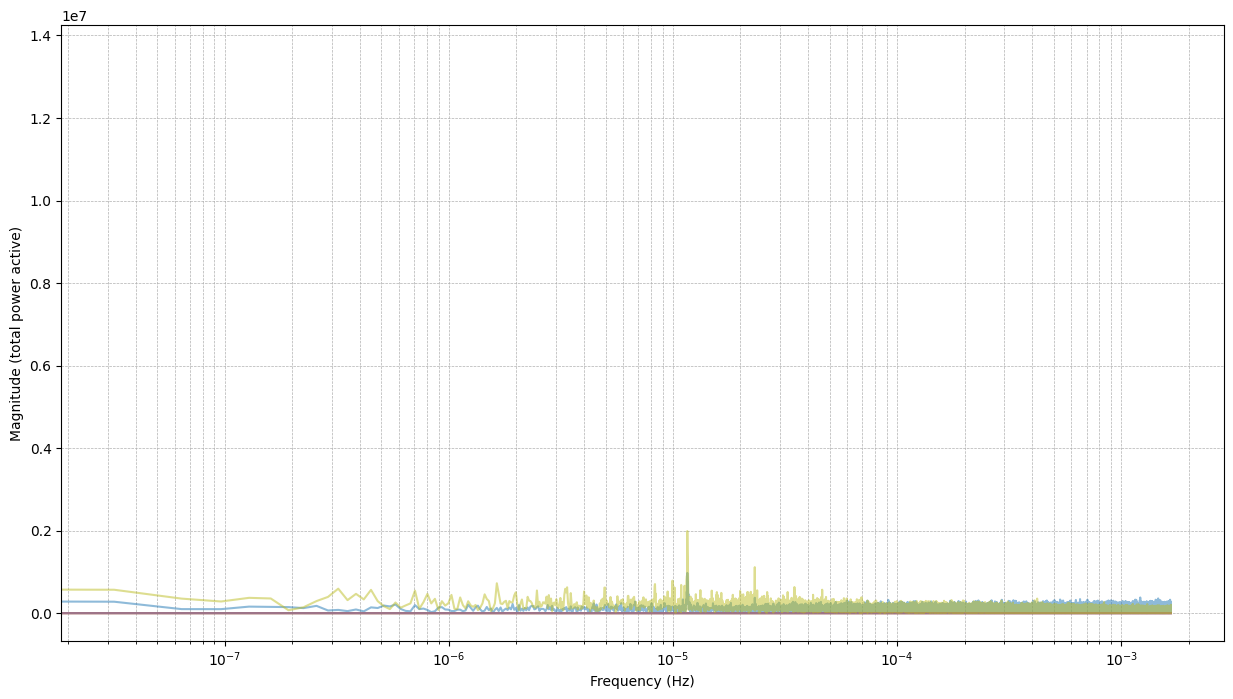

In [ ]:
period = 5 * 60 # 5 mins
fs = 1/period

plt.figure()

# check 10 sensors
start_sensor_index = 5
end_sensor_offset = 10
for id in smart_meter_df.device_id[start_sensor_index:start_sensor_index+end_sensor_offset]:
  meter_df_N = smart_meter_df[smart_meter_df.device_id == id]
  meter_df_N = meter_df_N.drop(columns=['device_id', 'serial_number'])
  signal = meter_df_N.groupby(meter_df_N['time']).mean()["total_power_active"]

  fft_result = np.fft.fft(signal)
  n = len(signal)
  freq = np.fft.fftfreq(n, d=1/fs)

  fft_result_shifted = np.fft.fftshift(fft_result)
  freq_shifted = np.fft.fftshift(freq)

  N = 10
  half_len = int(len(freq_shifted)/2)
  plt.plot(freq_shifted[half_len:],np.abs(fft_result_shifted[half_len:]), label=f"Device {id}", alpha=0.5)

plt.xscale("log")
plt.grid(True, which="both", linestyle="--", linewidth=0.5)
plt.xlabel("Frequency (Hz)")
plt.ylabel("Magnitude (total power active)")
plt.show()


## Seasonality analysis

In [109]:
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

### Hourly

#### `total_energy_active`

(-0.1, 1.1)

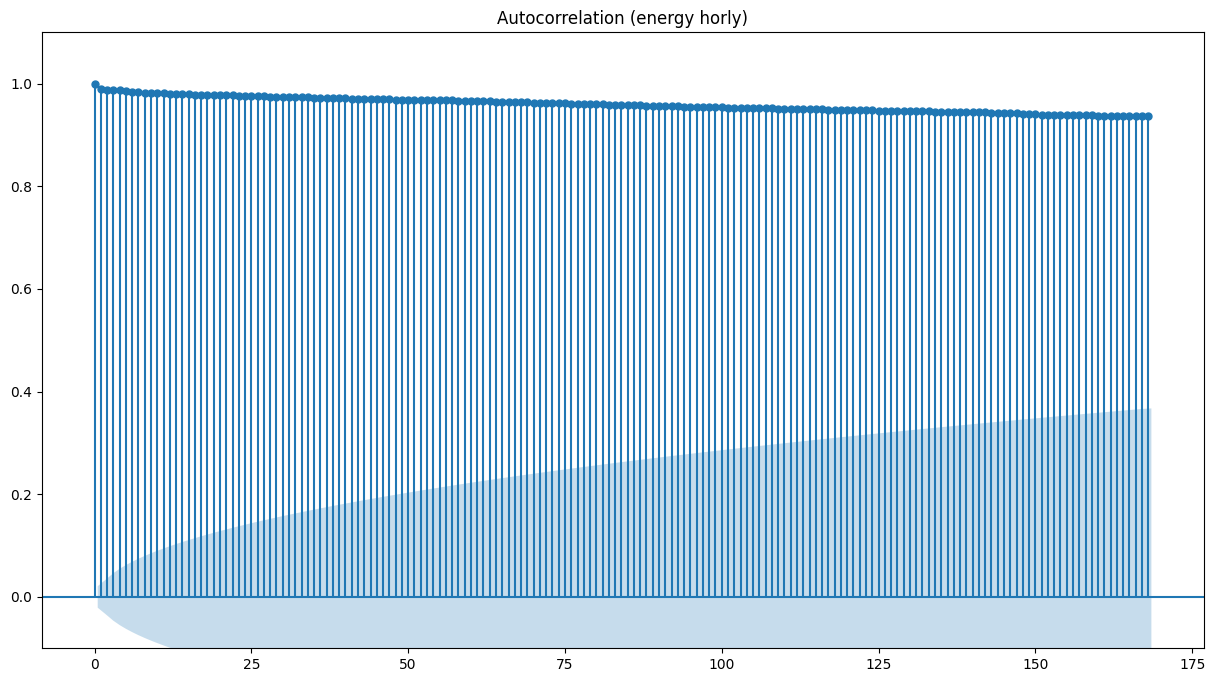

In [110]:
plot_acf(tot_eng_hour_endog.fillna(tot_eng_hour_endog.median()), lags=24*7, title='Autocorrelation (energy horly)');
plt.ylim(-0.1, 1.1)

(-0.1, 1.1)

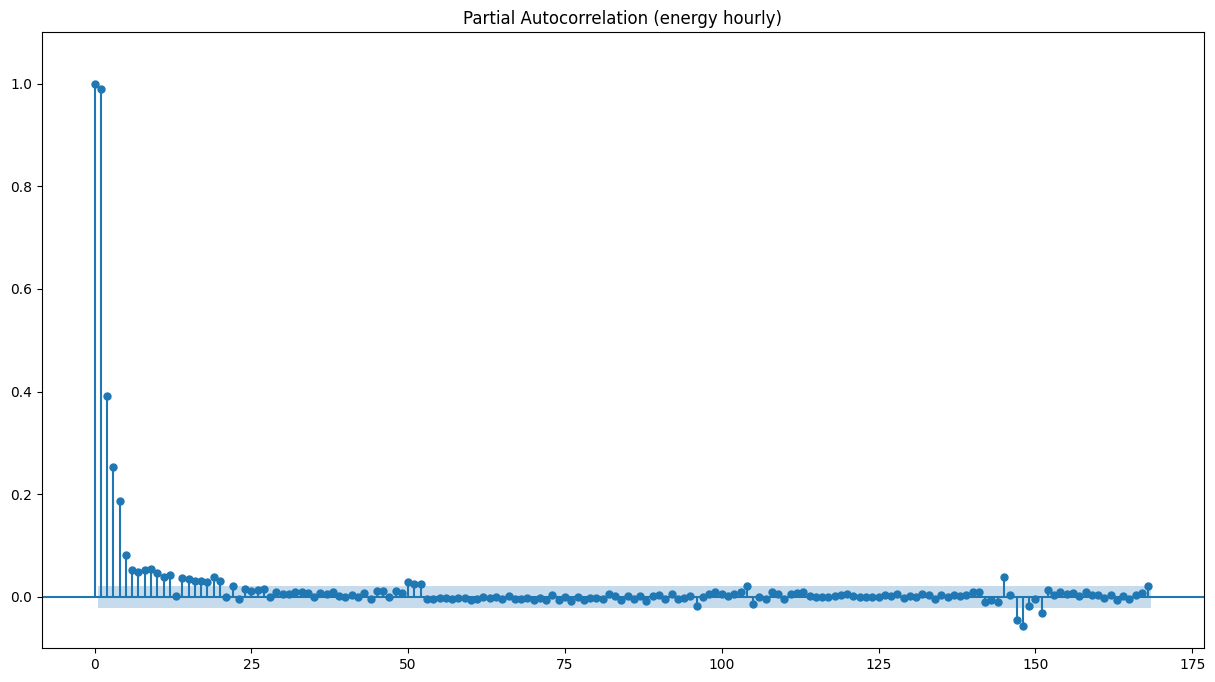

In [111]:
plot_pacf(tot_eng_hour_endog.fillna(tot_eng_hour_endog.median()), lags=24*7, title='Partial Autocorrelation (energy hourly)');
plt.ylim(-0.1, 1.1)

Biggest influence from **lag 1**

<Axes: >

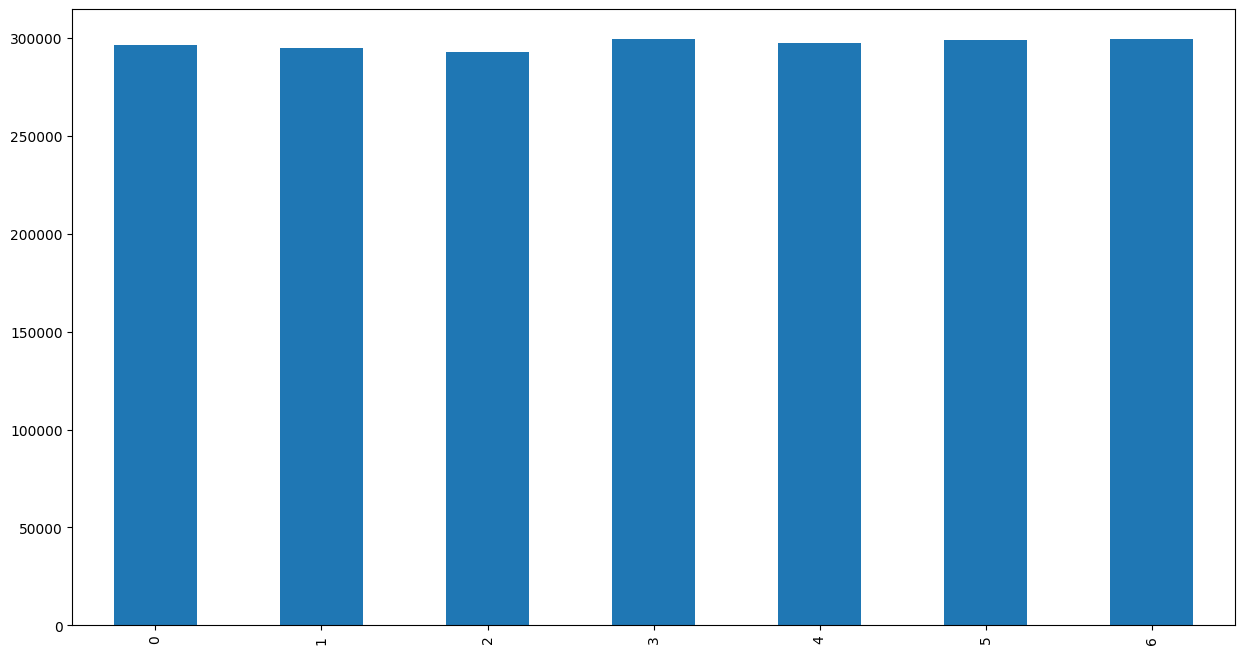

In [119]:
# Weekday median
tot_eng_hour_endog.groupby(tot_eng_hour_endog.index.weekday).median().plot(kind='bar')

<Axes: >

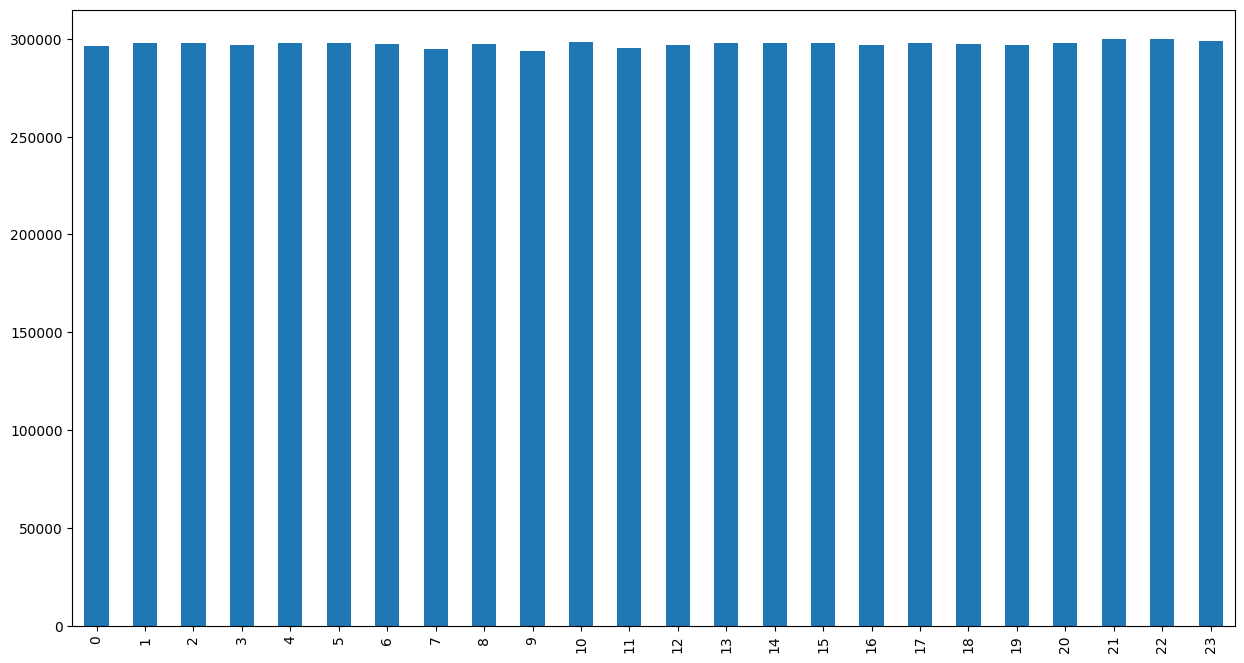

In [120]:
# Hourly median
tot_eng_hour_endog.groupby(tot_eng_hour_endog.index.hour).median().plot(kind='bar')

#### `total_energy_active.diff(1)`

(-0.7, 1.1)

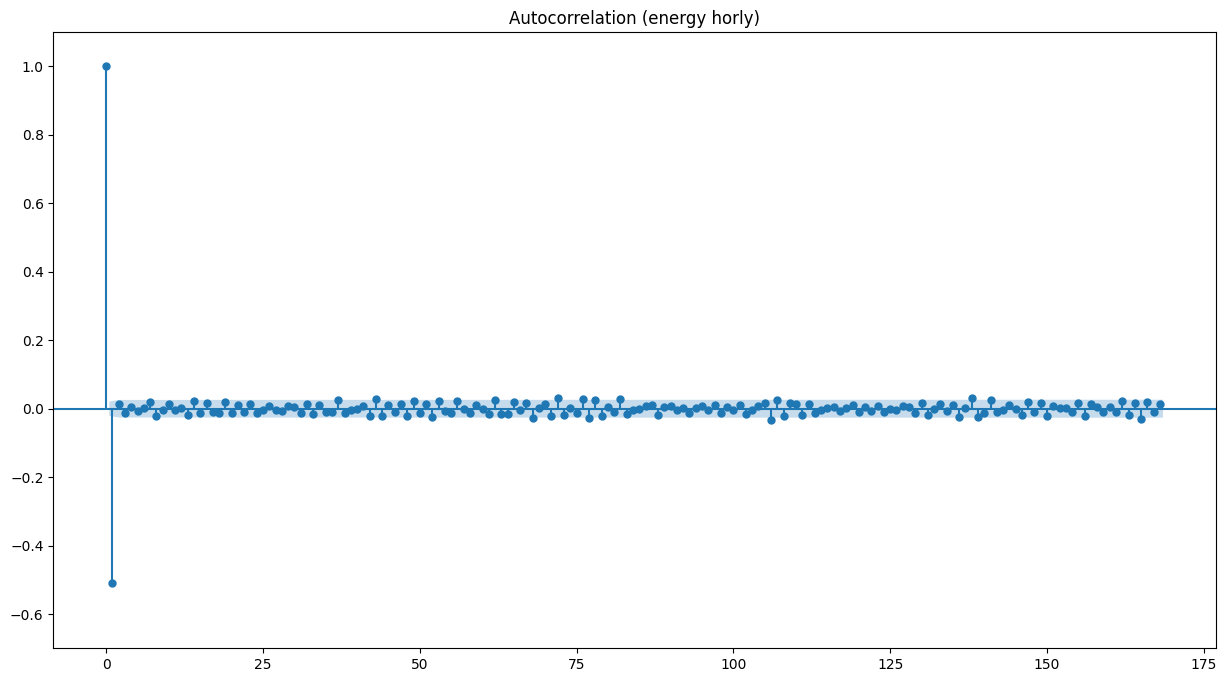

In [115]:
plot_acf(tot_eng_diff_hour_endog.fillna(tot_eng_diff_hour_endog.median()), lags=24*7, title='Autocorrelation (energy horly)');
plt.ylim(-0.7, 1.1)

(-0.7, 1.1)

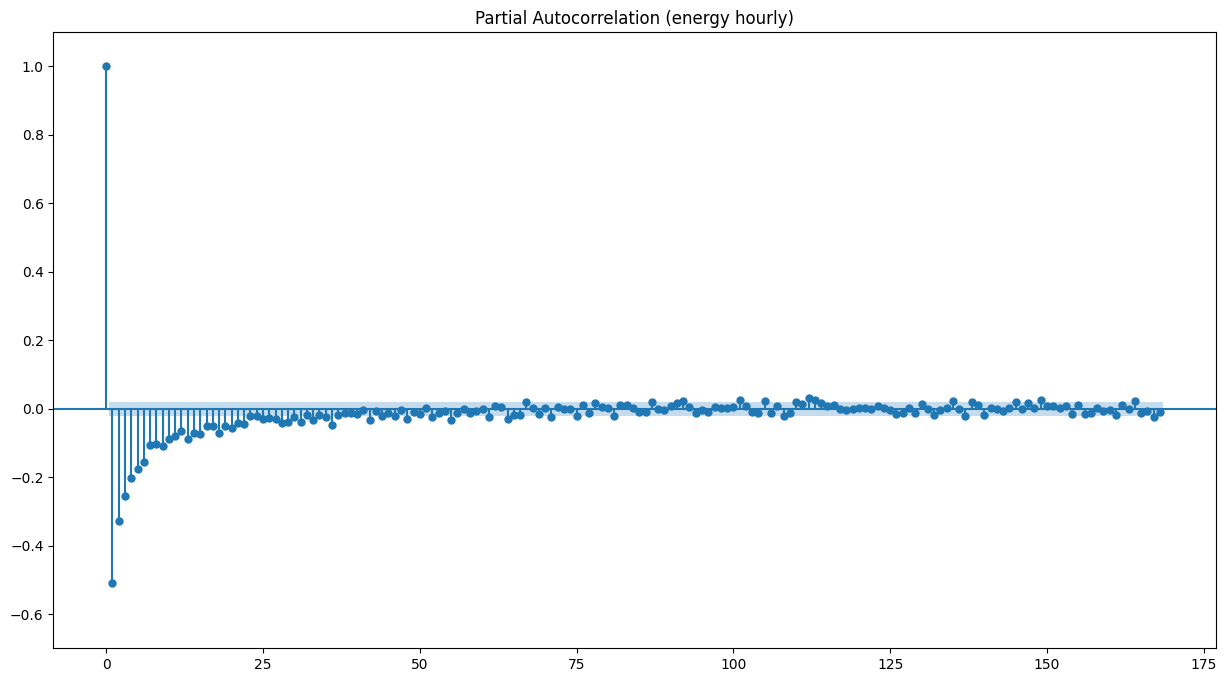

In [116]:
plot_pacf(tot_eng_diff_hour_endog.fillna(tot_eng_diff_hour_endog.median()), lags=24*7, title='Partial Autocorrelation (energy hourly)');
plt.ylim(-0.7, 1.1)

<Axes: >

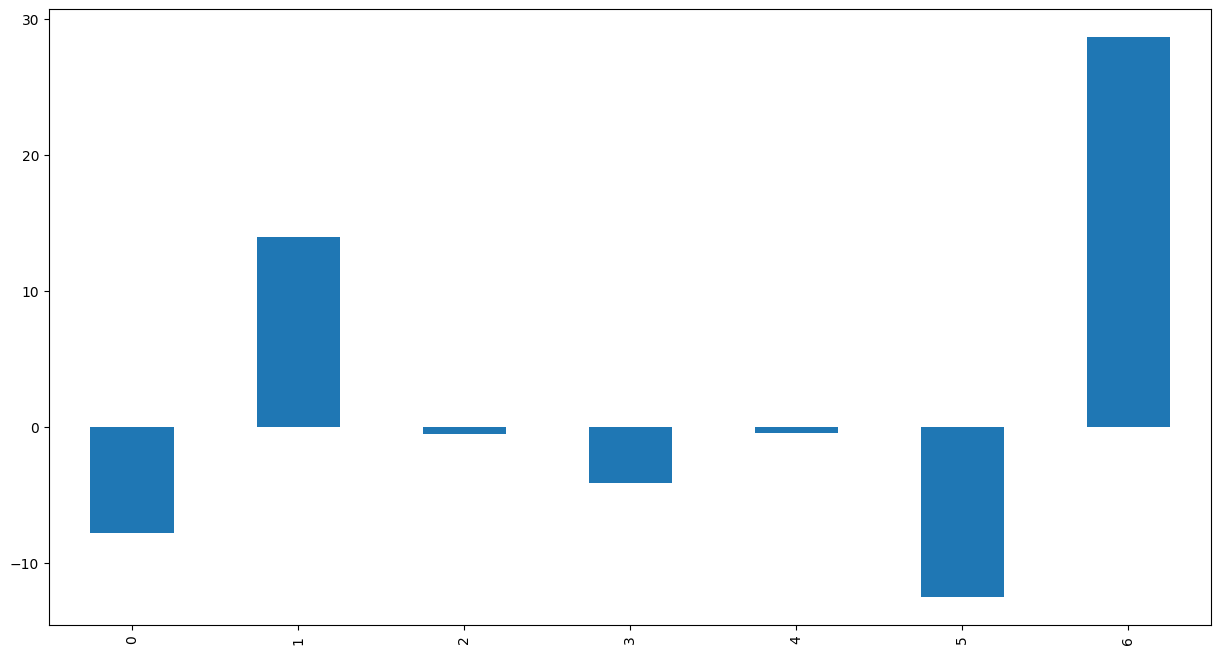

In [121]:
# Weekday median
tot_eng_diff_hour_endog.groupby(tot_eng_diff_hour_endog.index.weekday).median().plot(kind='bar')

<Axes: >

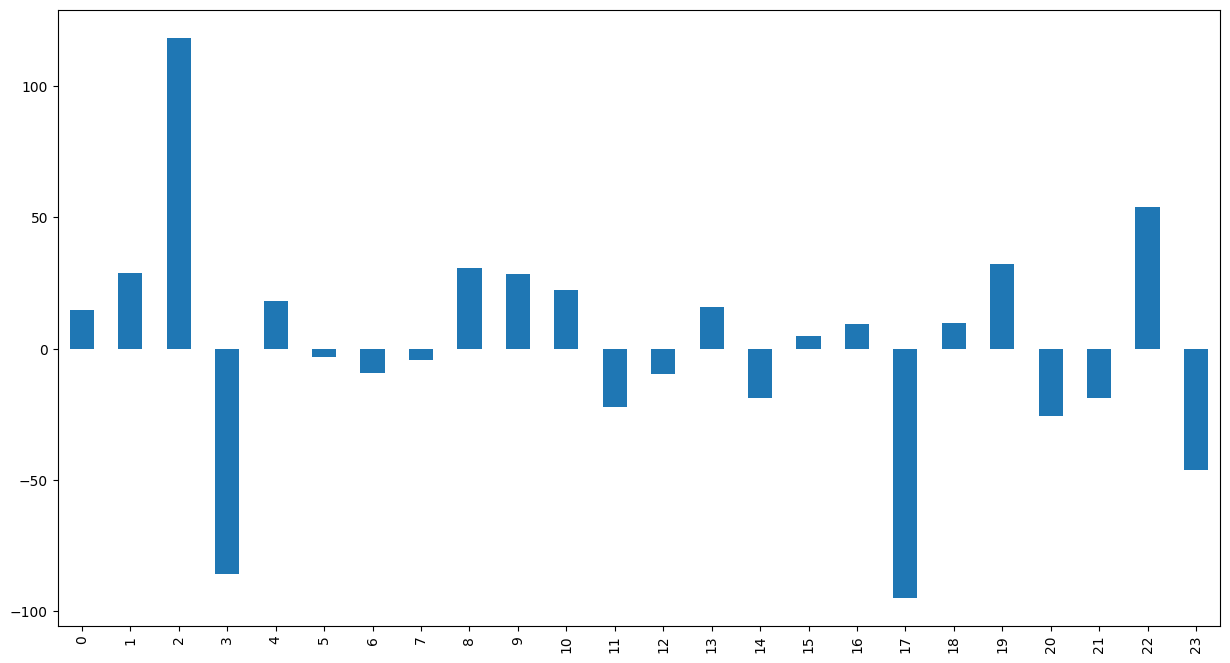

In [122]:
# Hourly median
tot_eng_diff_hour_endog.groupby(tot_eng_diff_hour_endog.index.hour).median().plot(kind='bar')

#### `total_power_active`

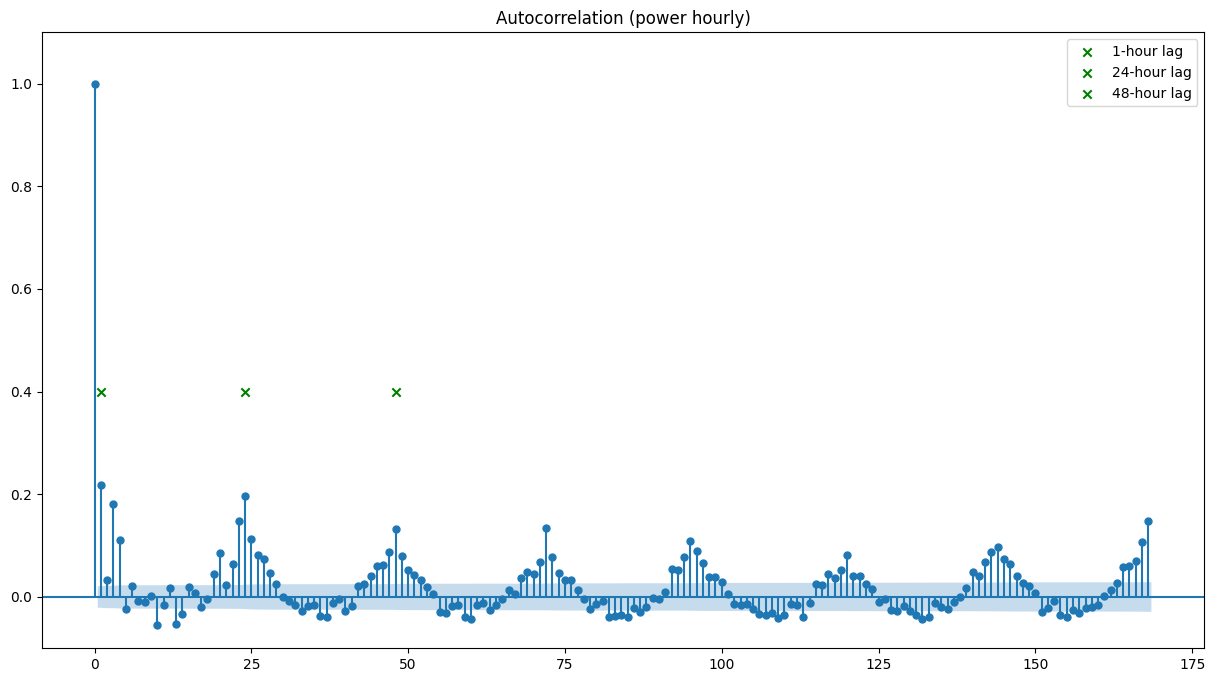

In [ ]:
plot_acf(tot_pow_hour_endog.fillna(tot_pow_hour_endog.median()), lags=24*7, title='Autocorrelation (power hourly)');
plt.scatter([1], [0.4], color='green', marker='x', label='1-hour lag')
plt.scatter([24], [0.4], color='green', marker='x', label='24-hour lag')
plt.scatter([48], [0.4], color='green', marker='x', label='48-hour lag')
plt.ylim(-0.1, 1.1)
plt.legend()

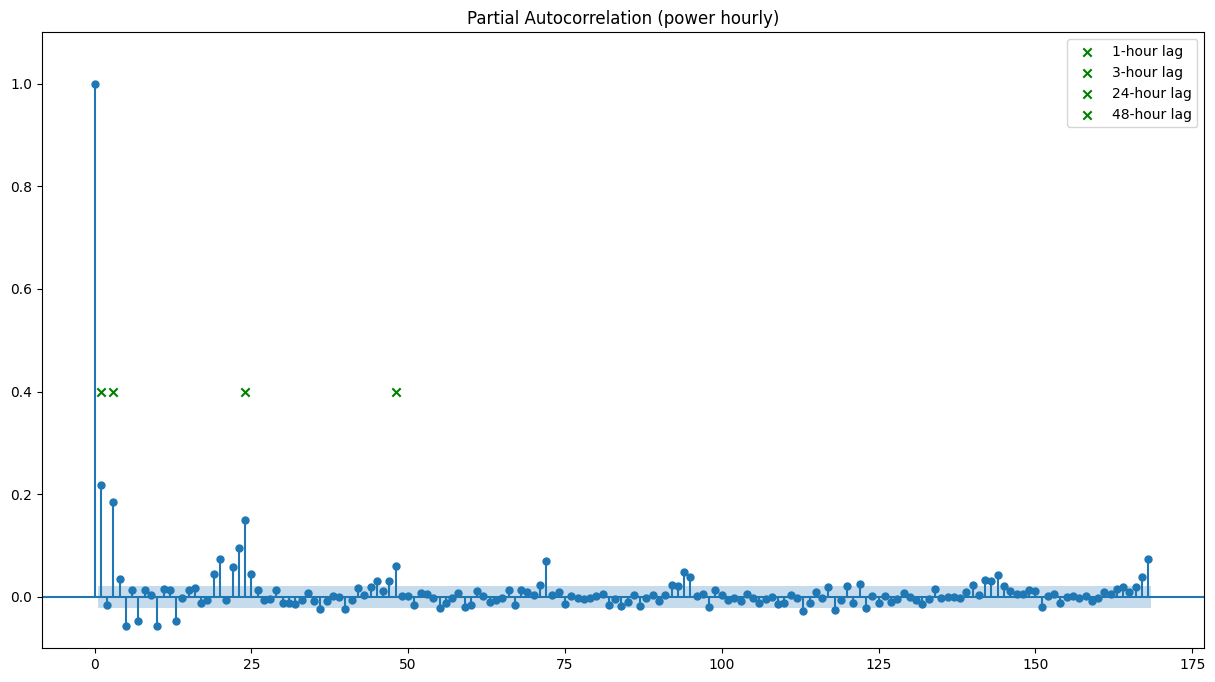

In [ ]:
plot_pacf(tot_pow_hour_endog.fillna(tot_pow_hour_endog.median()), lags=24*7, title='Partial Autocorrelation (power hourly)');
plt.scatter([1], [0.4], color='green', marker='x', label='1-hour lag')
plt.scatter([3], [0.4], color='green', marker='x', label='3-hour lag')
plt.scatter([24], [0.4], color='green', marker='x', label='24-hour lag')
plt.scatter([48], [0.4], color='green', marker='x', label='48-hour lag')
plt.ylim(-0.1, 1.1)
plt.legend()

The biggest influence from **lags 1 (1 hour before), 3, 24 and 48**

<Axes: >

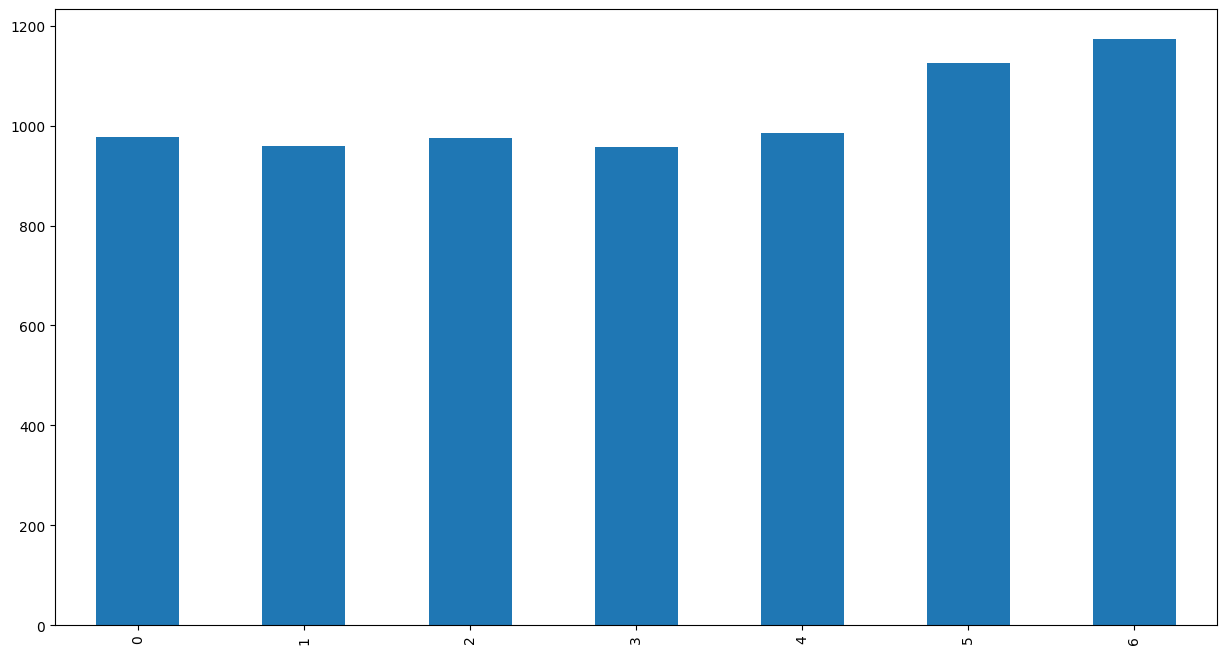

In [ ]:
# Weekday median
tot_pow_hour_endog.groupby(tot_pow_hour_endog.index.weekday).median().plot(kind='bar')

<Axes: >

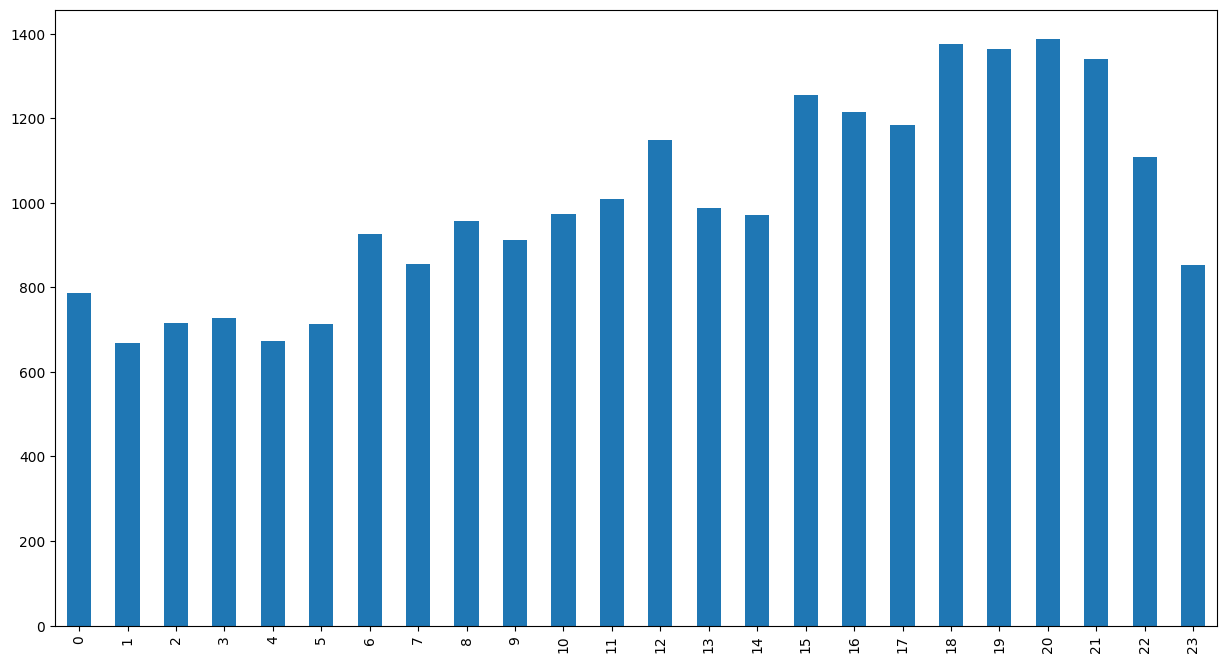

In [ ]:
# Hourly median
tot_pow_hour_endog.groupby(tot_pow_hour_endog.index.hour).median().plot(kind='bar')

### Daily

#### `total_energy_active`

(-0.7, 1.1)

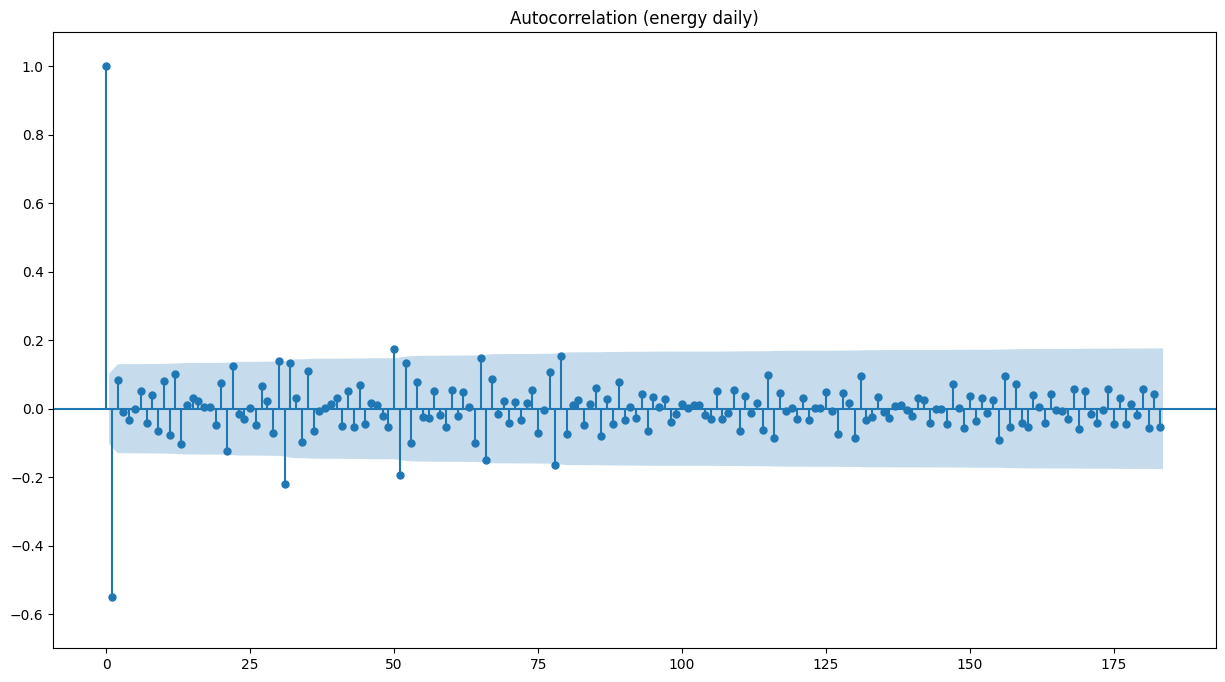

In [125]:
plot_acf(tot_eng_day_endog.fillna(tot_eng_day_endog.median()), lags=183, title='Autocorrelation (energy daily)');
plt.ylim(-0.7, 1.1)

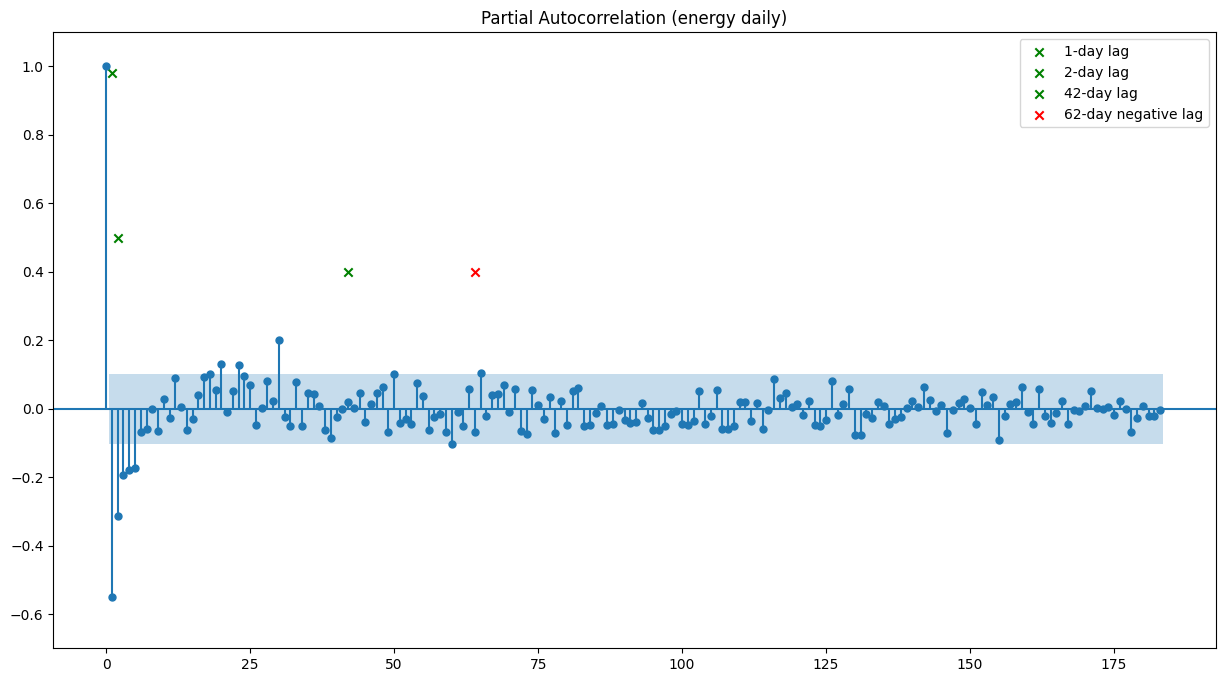

In [126]:
plot_pacf(tot_eng_day_endog.fillna(tot_eng_day_endog.median()), lags=183, title='Partial Autocorrelation (energy daily)');
plt.ylim(-0.7, 1.1)
plt.scatter([1], [0.98], color='green', marker='x', label='1-day lag')
plt.scatter([2], [0.5], color='green', marker='x', label='2-day lag')
plt.scatter([42], [0.4], color='green', marker='x', label='42-day lag')
plt.scatter([64], [0.4], color='red', marker='x', label='62-day negative lag')
plt.legend()

Biggest influence from **lags 1, 2, 42 and 62 days**

#### `total_power_active`

(-0.5, 1.1)

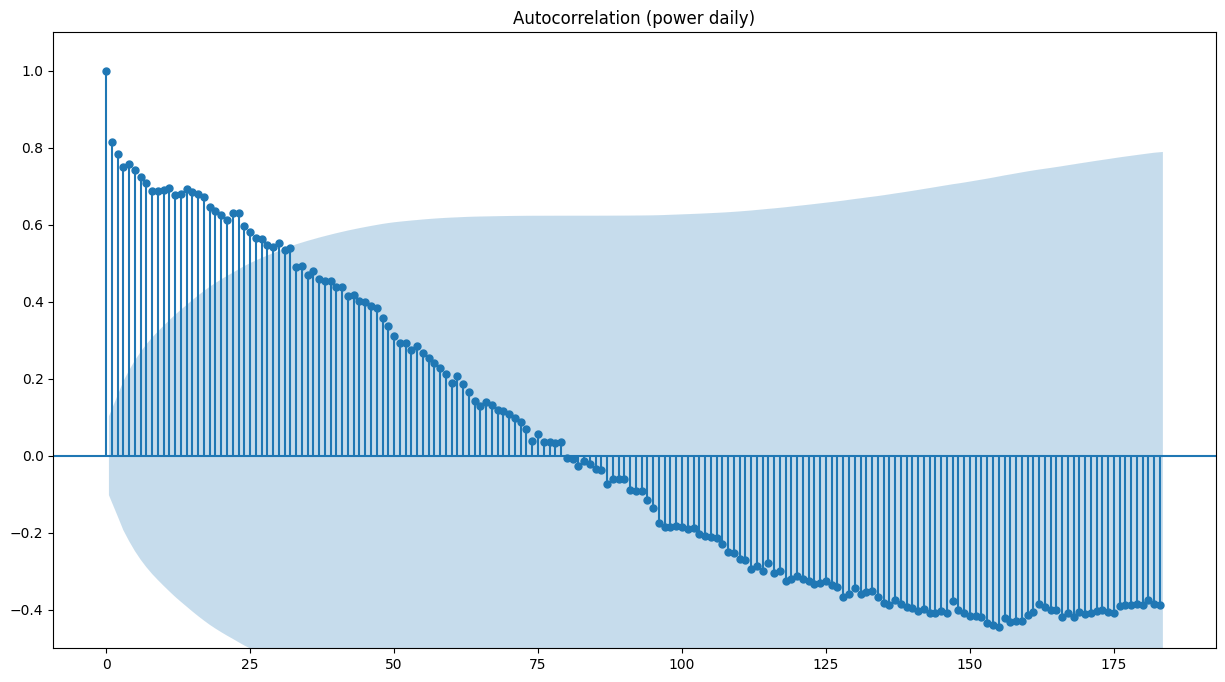

In [127]:
plot_acf(tot_pow_day_endog.fillna(tot_pow_day_endog.median()), lags=183, title='Autocorrelation (power daily)');
plt.ylim(-0.5, 1.1)

(-0.5, 1.1)

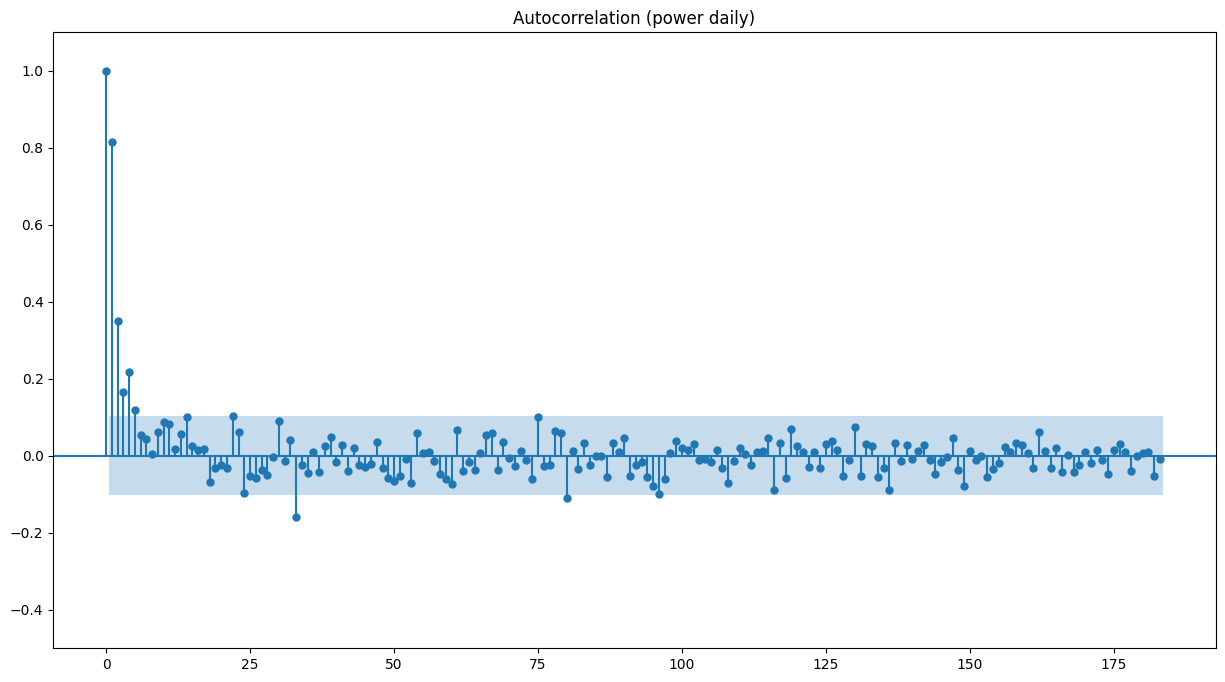

In [128]:
plot_pacf(tot_pow_day_endog.fillna(tot_pow_day_endog.median()), lags=183, title='Autocorrelation (power daily)');
plt.ylim(-0.5, 1.1)

Biggest influence from **lags 1 and 2 days**

### Seasonal decomposition with (MSTL)

MSTL - Season-Trend decomposition using LOESS for multiple seasonalities

#### Hourly

##### `total_energy_active`

In [ ]:
from statsmodels.tsa.seasonal import MSTL

hourly_eng_decomposition = MSTL(
    tot_eng_hour_endog.fillna(tot_eng_hour_endog.median()),
    periods=[24, 24*7]
    ).fit()

In [ ]:
hourly_eng_decomposition.plot();

##### `total_power_active`

In [ ]:
hourly_pow_decomposition = MSTL(
    tot_pow_hour_endog.fillna(tot_pow_hour_endog.median()),
    periods=[24, 24*7]
    ).fit()

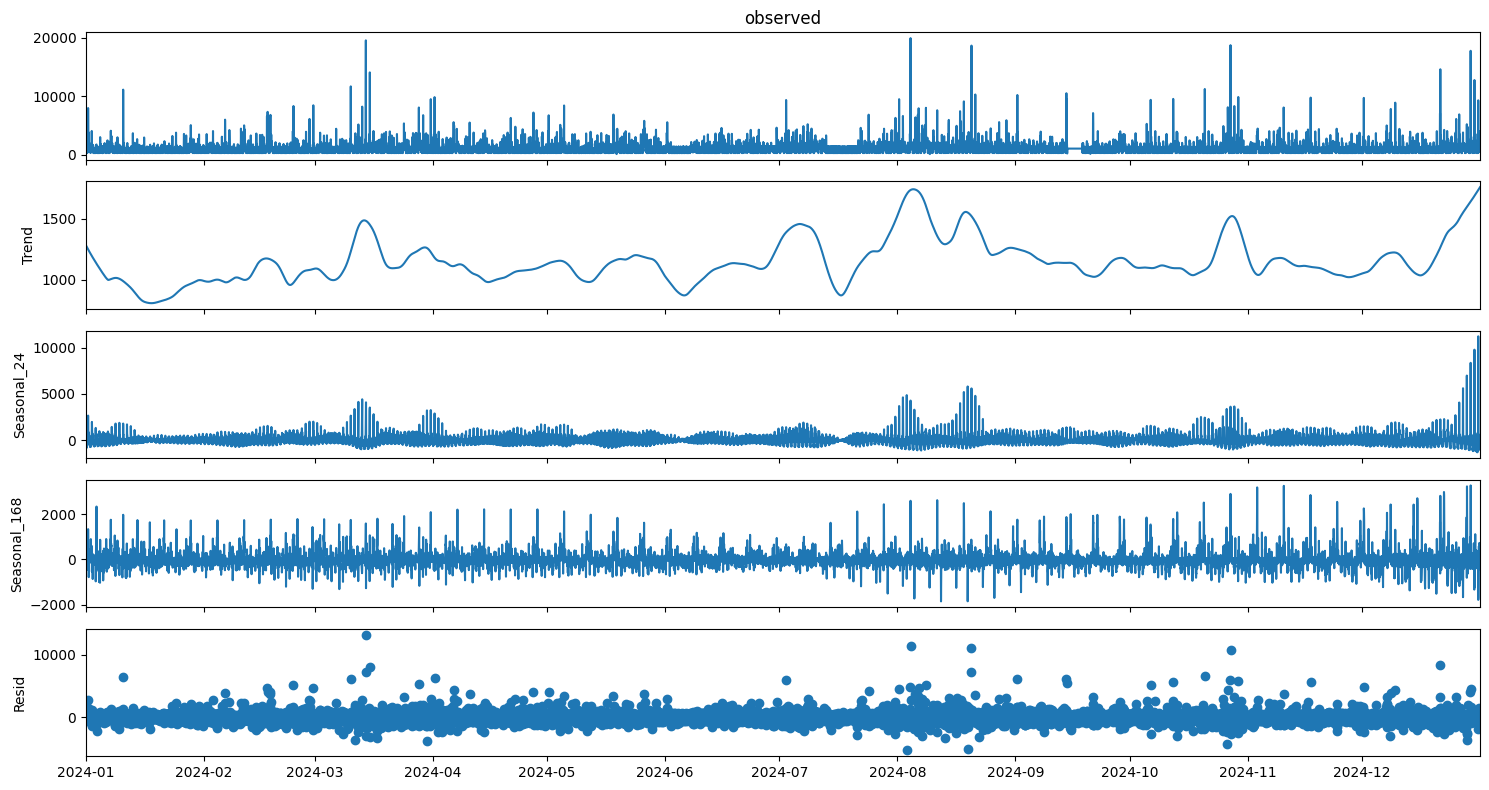

In [ ]:
hourly_pow_decomposition.plot();

#### Daily

##### `total_energy_active`

In [ ]:
daily_eng_decomposition = MSTL(
    tot_eng_day_endog.fillna(tot_eng_day_endog.median()),
    periods=[7]
    ).fit()

In [ ]:
daily_eng_decomposition.plot();

##### `total_power_active`

In [ ]:
daily_pow_decomposition = MSTL(
    tot_pow_day_endog.fillna(tot_pow_day_endog.median()),
    periods=[24, 24*7]
    ).fit()

In [ ]:
daily_pow_decomposition.plot();